# YOLOv8s Training on RDD2022

This notebook trains **YOLOv8s** on the RDD2022 road damage dataset (5 classes) with the Ultralytics package. All three models in this project use the same settings so the comparison is fair: image size 640, batch size 16, 50 epochs, early-stopping patience 15 and seed 42.

**Steps:** environment, dataset checks, dataset YAML, label sanity check, training, results.

*Runs on Kaggle with a GPU. The data is the Kaggle YOLO-format version of RDD2022.*

## 1. Environment

Checks the GPU, installs Ultralytics, imports the libraries, prints the library versions and sets the random seed (42).

In [1]:
!nvidia-smi

Thu Aug  6 00:14:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.5 MB/s eta 0:00:00


In [3]:
import os
import random
import shutil
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
import yaml

from IPython.display import Image, display
from PIL import Image as PILImage
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [4]:
print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch version: 2.10.0+cu128
Ultralytics version: 8.4.115
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


## 2. Dataset checks

Points to the RDD2022 data, checks that the train/val/test folders exist, lists the accepted image types, and counts the annotations per class in each split. Only class IDs 0 to 4 are valid, so anything else is flagged.

In [6]:
SOURCE_DATASET = Path(
    "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT"
)

WORKING_DIRECTORY = Path("/kaggle/working")

PROJECT_DIRECTORY = (
    WORKING_DIRECTORY / "RoadDamageProject"
)

RUN_NAME = "YOLOv8s_RDD2022_5class"

RUN_DIRECTORY = (
    PROJECT_DIRECTORY / RUN_NAME
)

YAML_PATH = (
    WORKING_DIRECTORY / "rdd2022_5class.yaml"
)

print("Dataset:", SOURCE_DATASET)
print("Dataset exists:", SOURCE_DATASET.exists())
print("Project directory:", PROJECT_DIRECTORY)
print("Run directory:", RUN_DIRECTORY)
print("YAML path:", YAML_PATH)

Dataset: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT
Dataset exists: True
Project directory: /kaggle/working/RoadDamageProject
Run directory: /kaggle/working/RoadDamageProject/YOLOv8s_RDD2022_5class
YAML path: /kaggle/working/rdd2022_5class.yaml


In [7]:
required_directories = []

for split in ["train", "val", "test"]:
    required_directories.extend(
        [
            SOURCE_DATASET / split / "images",
            SOURCE_DATASET / split / "labels"
        ]
    )

missing_directories = [
    path
    for path in required_directories
    if not path.exists()
]

if missing_directories:
    print("Missing directories:")

    for path in missing_directories:
        print(path)

    raise FileNotFoundError(
        "The expected RDD2022 folder structure was not found."
    )

print("All required dataset directories were found.")

All required dataset directories were found.


In [8]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
    ".tif",
    ".tiff"
}

dataset_summary = []

for split in ["train", "val", "test"]:
    images_directory = (
        SOURCE_DATASET / split / "images"
    )

    labels_directory = (
        SOURCE_DATASET / split / "labels"
    )

    image_files = [
        path
        for path in images_directory.iterdir()
        if path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    label_files = list(
        labels_directory.glob("*.txt")
    )

    image_stems = {
        path.stem for path in image_files
    }

    label_stems = {
        path.stem for path in label_files
    }

    images_without_labels = (
        image_stems - label_stems
    )

    labels_without_images = (
        label_stems - image_stems
    )

    dataset_summary.append(
        {
            "split": split,
            "images": len(image_files),
            "label_files": len(label_files),
            "images_without_labels": len(
                images_without_labels
            ),
            "labels_without_images": len(
                labels_without_images
            )
        }
    )

dataset_summary_df = pd.DataFrame(dataset_summary)

display(dataset_summary_df)

,split,images,label_files,images_without_labels,labels_without_images
0,train,26869,26869,0,0
1,val,5758,5758,0,0
2,test,5758,5758,0,0


In [9]:
VALID_CLASSES = {0, 1, 2, 3, 4}

CLASS_NAMES = [
    "longitudinal crack",
    "transverse crack",
    "alligator crack",
    "other corruption",
    "Pothole"
]

class_counts = Counter()
invalid_annotations = []

for split in ["train", "val", "test"]:
    labels_directory = (
        SOURCE_DATASET / split / "labels"
    )

    for label_path in labels_directory.glob("*.txt"):
        with open(
            label_path,
            "r",
            encoding="utf-8"
        ) as label_file:

            for line_number, line in enumerate(
                label_file,
                start=1
            ):
                original_line = line.strip()

                if not original_line:
                    continue

                parts = original_line.split()

                if len(parts) != 5:
                    invalid_annotations.append(
                        {
                            "split": split,
                            "file": str(label_path),
                            "line": line_number,
                            "annotation": original_line,
                            "reason": "Expected exactly 5 values"
                        }
                    )
                    continue

                try:
                    class_value = float(parts[0])

                    x_center = float(parts[1])
                    y_center = float(parts[2])
                    width = float(parts[3])
                    height = float(parts[4])

                except ValueError:
                    invalid_annotations.append(
                        {
                            "split": split,
                            "file": str(label_path),
                            "line": line_number,
                            "annotation": original_line,
                            "reason": "Non-numeric value"
                        }
                    )
                    continue

                if not class_value.is_integer():
                    invalid_annotations.append(
                        {
                            "split": split,
                            "file": str(label_path),
                            "line": line_number,
                            "annotation": original_line,
                            "reason": "Class ID is not an integer"
                        }
                    )
                    continue

                class_id = int(class_value)

                if class_id not in VALID_CLASSES:
                    invalid_annotations.append(
                        {
                            "split": split,
                            "file": str(label_path),
                            "line": line_number,
                            "annotation": original_line,
                            "reason": (
                                f"Unknown class ID {class_id}"
                            )
                        }
                    )
                    continue

                coordinates_are_valid = (
                    0 <= x_center <= 1
                    and 0 <= y_center <= 1
                    and 0 < width <= 1
                    and 0 < height <= 1
                )

                if not coordinates_are_valid:
                    invalid_annotations.append(
                        {
                            "split": split,
                            "file": str(label_path),
                            "line": line_number,
                            "annotation": original_line,
                            "reason": (
                                "Invalid normalized bounding box"
                            )
                        }
                    )
                    continue

                class_counts[(split, class_id)] += 1

In [10]:
found_class_ids = sorted(
    {
        class_id
        for (_, class_id), count
        in class_counts.items()
        if count > 0
    }
)

print("Class IDs found:", found_class_ids)
print("Expected class IDs:", sorted(VALID_CLASSES))
print("Invalid annotation rows:", len(invalid_annotations))

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    total_objects = 0

    for class_id, class_name in enumerate(CLASS_NAMES):
        count = class_counts[(split, class_id)]
        total_objects += count

        print(
            f"Class {class_id} "
            f"({class_name}): {count}"
        )

    print("Total objects:", total_objects)

if invalid_annotations:
    print("\nFirst invalid annotations:")

    for item in invalid_annotations[:20]:
        print(item)

Class IDs found: [0, 1, 2, 3, 4]
Expected class IDs: [0, 1, 2, 3, 4]
Invalid annotation rows: 1

TRAIN
Class 0 (longitudinal crack): 18201
Class 1 (transverse crack): 8386
Class 2 (alligator crack): 7526
Class 3 (other corruption): 7554
Class 4 (Pothole): 4628
Total objects: 46295

VAL
Class 0 (longitudinal crack): 3890
Class 1 (transverse crack): 1769
Class 2 (alligator crack): 1553
Class 3 (other corruption): 1564
Class 4 (Pothole): 965
Total objects: 9741

TEST
Class 0 (longitudinal crack): 3925
Class 1 (transverse crack): 1675
Class 2 (alligator crack): 1537
Class 3 (other corruption): 1587
Class 4 (Pothole): 951
Total objects: 9675

First invalid annotations:
{'split': 'train', 'file': '/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/labels/Japan_001265.txt', 'line': 4, 'annotation': '2 0.330000 0.790833 0.000000 0.001667', 'reason': 'Invalid normalized bounding box'}


## 3. Dataset YAML

Writes the YAML file that tells YOLO where the train, val and test images are and what the 5 class names are. It is read back to confirm it is correct, and old `.cache` files are deleted so YOLO re-reads the labels.

In [11]:
dataset_configuration = {
    "path": str(SOURCE_DATASET),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": CLASS_NAMES
}

with open(
    YAML_PATH,
    "w",
    encoding="utf-8"
) as yaml_file:
    yaml.safe_dump(
        dataset_configuration,
        yaml_file,
        sort_keys=False,
        allow_unicode=True
    )

print("Created YAML file:")
print(YAML_PATH)
print()
print(YAML_PATH.read_text())

Created YAML file:
/kaggle/working/rdd2022_5class.yaml

path: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT
train: train/images
val: val/images
test: test/images
names:
- longitudinal crack
- transverse crack
- alligator crack
- other corruption
- Pothole



In [12]:
with open(
    YAML_PATH,
    "r",
    encoding="utf-8"
) as yaml_file:
    loaded_configuration = yaml.safe_load(yaml_file)

print("Number of classes:", len(loaded_configuration["names"]))
print("Classes:")

for class_id, class_name in enumerate(
    loaded_configuration["names"]
):
    print(class_id, ":", class_name)

assert len(loaded_configuration["names"]) == 5
assert loaded_configuration["names"][4] == "Pothole"

print("\nFive-class YAML verification passed.")

Number of classes: 5
Classes:
0 : longitudinal crack
1 : transverse crack
2 : alligator crack
3 : other corruption
4 : Pothole

Five-class YAML verification passed.


In [13]:
cache_files = list(
    SOURCE_DATASET.rglob("*.cache")
)

print("Cache files found:", len(cache_files))

for cache_file in cache_files:
    print("Removing:", cache_file)
    cache_file.unlink()

print("Old dataset cache files removed.")

Cache files found: 0
Old dataset cache files removed.


## 4. Visual check of the labels

Converts the YOLO label format into pixel coordinates and shows a few random training images with their labels. This is a quick check that the labels line up with the images.

In [14]:
def read_yolo_annotations(
    label_path,
    image_width,
    image_height
):
    annotations = []

    if not label_path.exists():
        return annotations

    with open(
        label_path,
        "r",
        encoding="utf-8"
    ) as label_file:

        for line in label_file:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id = int(float(parts[0]))
            x_center = float(parts[1]) * image_width
            y_center = float(parts[2]) * image_height
            width = float(parts[3]) * image_width
            height = float(parts[4]) * image_height

            x_min = x_center - width / 2
            y_min = y_center - height / 2

            annotations.append(
                {
                    "class_id": class_id,
                    "x_min": x_min,
                    "y_min": y_min,
                    "width": width,
                    "height": height
                }
            )

    return annotations

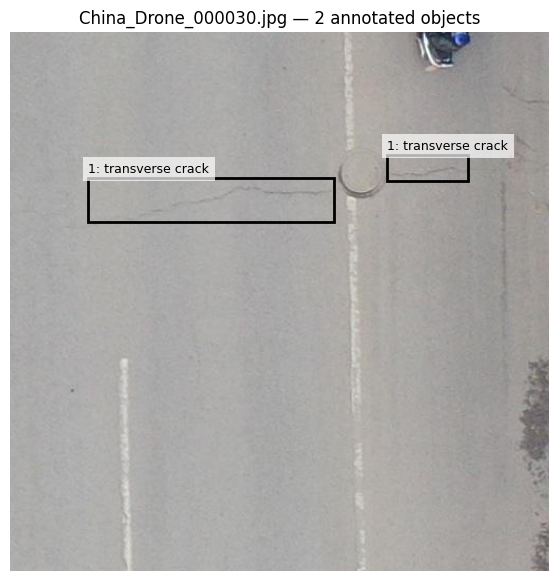

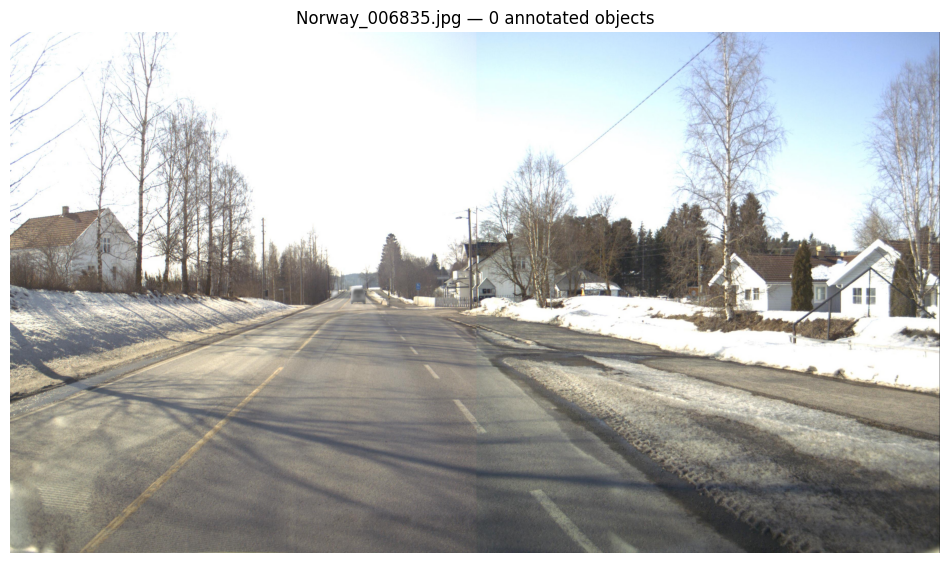

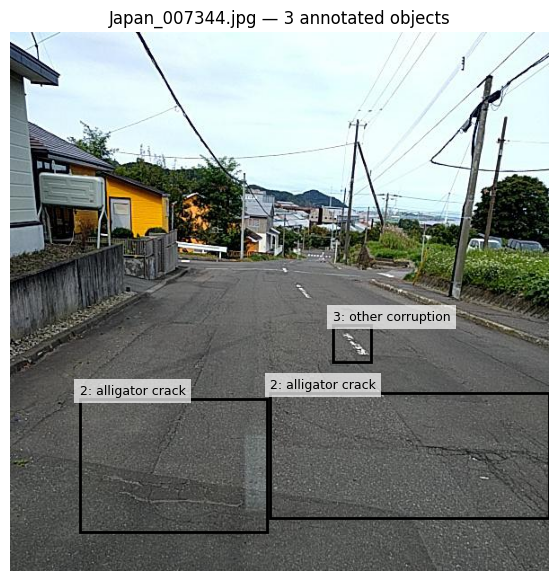

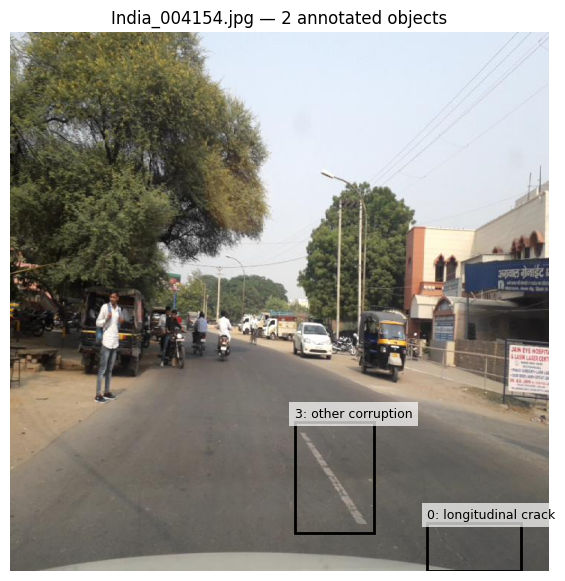

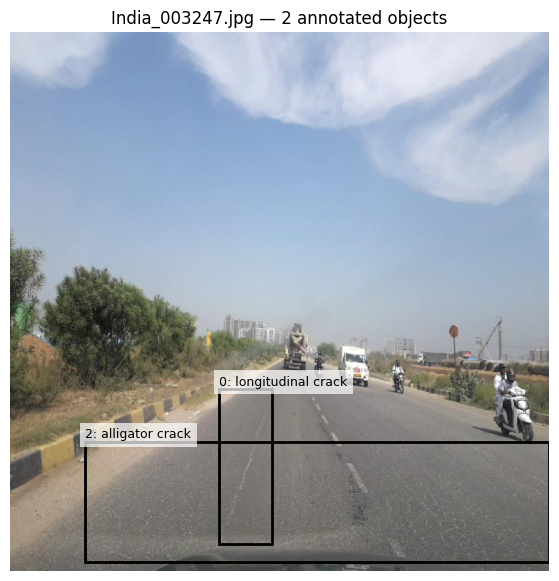

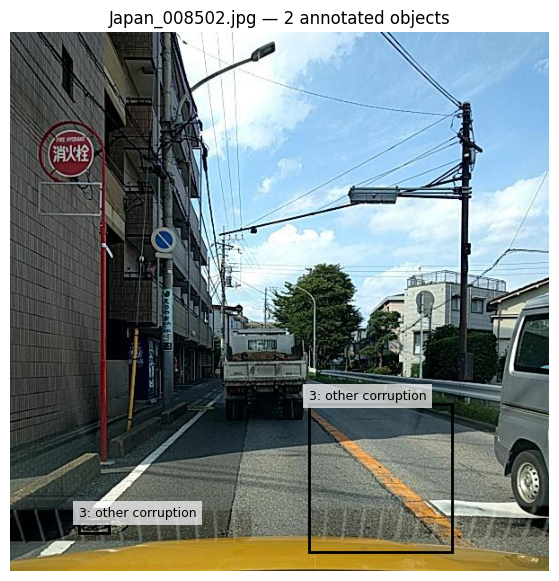

In [15]:
train_images_directory = (
    SOURCE_DATASET / "train" / "images"
)

train_labels_directory = (
    SOURCE_DATASET / "train" / "labels"
)

train_images = [
    path
    for path in train_images_directory.iterdir()
    if path.suffix.lower() in IMAGE_EXTENSIONS
]

random.seed(SEED)
sample_images = random.sample(
    train_images,
    k=min(6, len(train_images))
)

for image_path in sample_images:
    image = PILImage.open(image_path).convert("RGB")

    image_width, image_height = image.size

    label_path = (
        train_labels_directory /
        f"{image_path.stem}.txt"
    )

    annotations = read_yolo_annotations(
        label_path,
        image_width,
        image_height
    )

    plt.figure(figsize=(12, 7))
    plt.imshow(image)

    current_axis = plt.gca()

    for annotation in annotations:
        class_id = annotation["class_id"]

        rectangle = plt.Rectangle(
            (
                annotation["x_min"],
                annotation["y_min"]
            ),
            annotation["width"],
            annotation["height"],
            fill=False,
            linewidth=2
        )

        current_axis.add_patch(rectangle)

        current_axis.text(
            annotation["x_min"],
            max(annotation["y_min"] - 5, 0),
            f"{class_id}: {CLASS_NAMES[class_id]}",
            fontsize=9,
            bbox={
                "facecolor": "white",
                "alpha": 0.7,
                "edgecolor": "none"
            }
        )

    plt.title(
        f"{image_path.name} — "
        f"{len(annotations)} annotated objects"
    )

    plt.axis("off")
    plt.show()

## 5. Train YOLOv8s

Creates the output folder (it stops if a run with the same name already exists, so old results are not overwritten), loads the pretrained `yolov8s.pt` weights and trains with: 50 epochs, image size 640, batch size 16, patience 15, seed 42, automatic optimizer choice and mixed precision (AMP).

In [16]:
PROJECT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)

if RUN_DIRECTORY.exists():
    raise FileExistsError(
        f"{RUN_DIRECTORY} already exists.\n"
        "Change RUN_NAME or remove the old run intentionally "
        "before starting a new experiment."
    )

print("Output directory is ready.")

Output directory is ready.


In [17]:
model = YOLO("yolov8s.pt")

print("YOLOv8s pretrained model loaded.")

YOLOv8s pretrained model loaded.


In [18]:
model = YOLO("yolov8s.pt")

training_results = model.train(
    data=str(YAML_PATH),

    epochs=50,
    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    patience=15,

    seed=SEED,
    deterministic=True,

    pretrained=True,
    optimizer="auto",

    cache=False,
    amp=True,

    save=True,
    save_period=5,
    plots=True,

    project=str(PROJECT_DIRECTORY),
    name=RUN_NAME,
    exist_ok=False,

    verbose=True
)

Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/rdd2022_5class.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8s_RDD2022_5class, n

## 6. Training results

Shows the plots saved by Ultralytics (training curves, confusion matrices, precision/recall/F1 curves), loads `results.csv` with the metrics of every epoch, and prints the metrics of the final epoch.


results.png


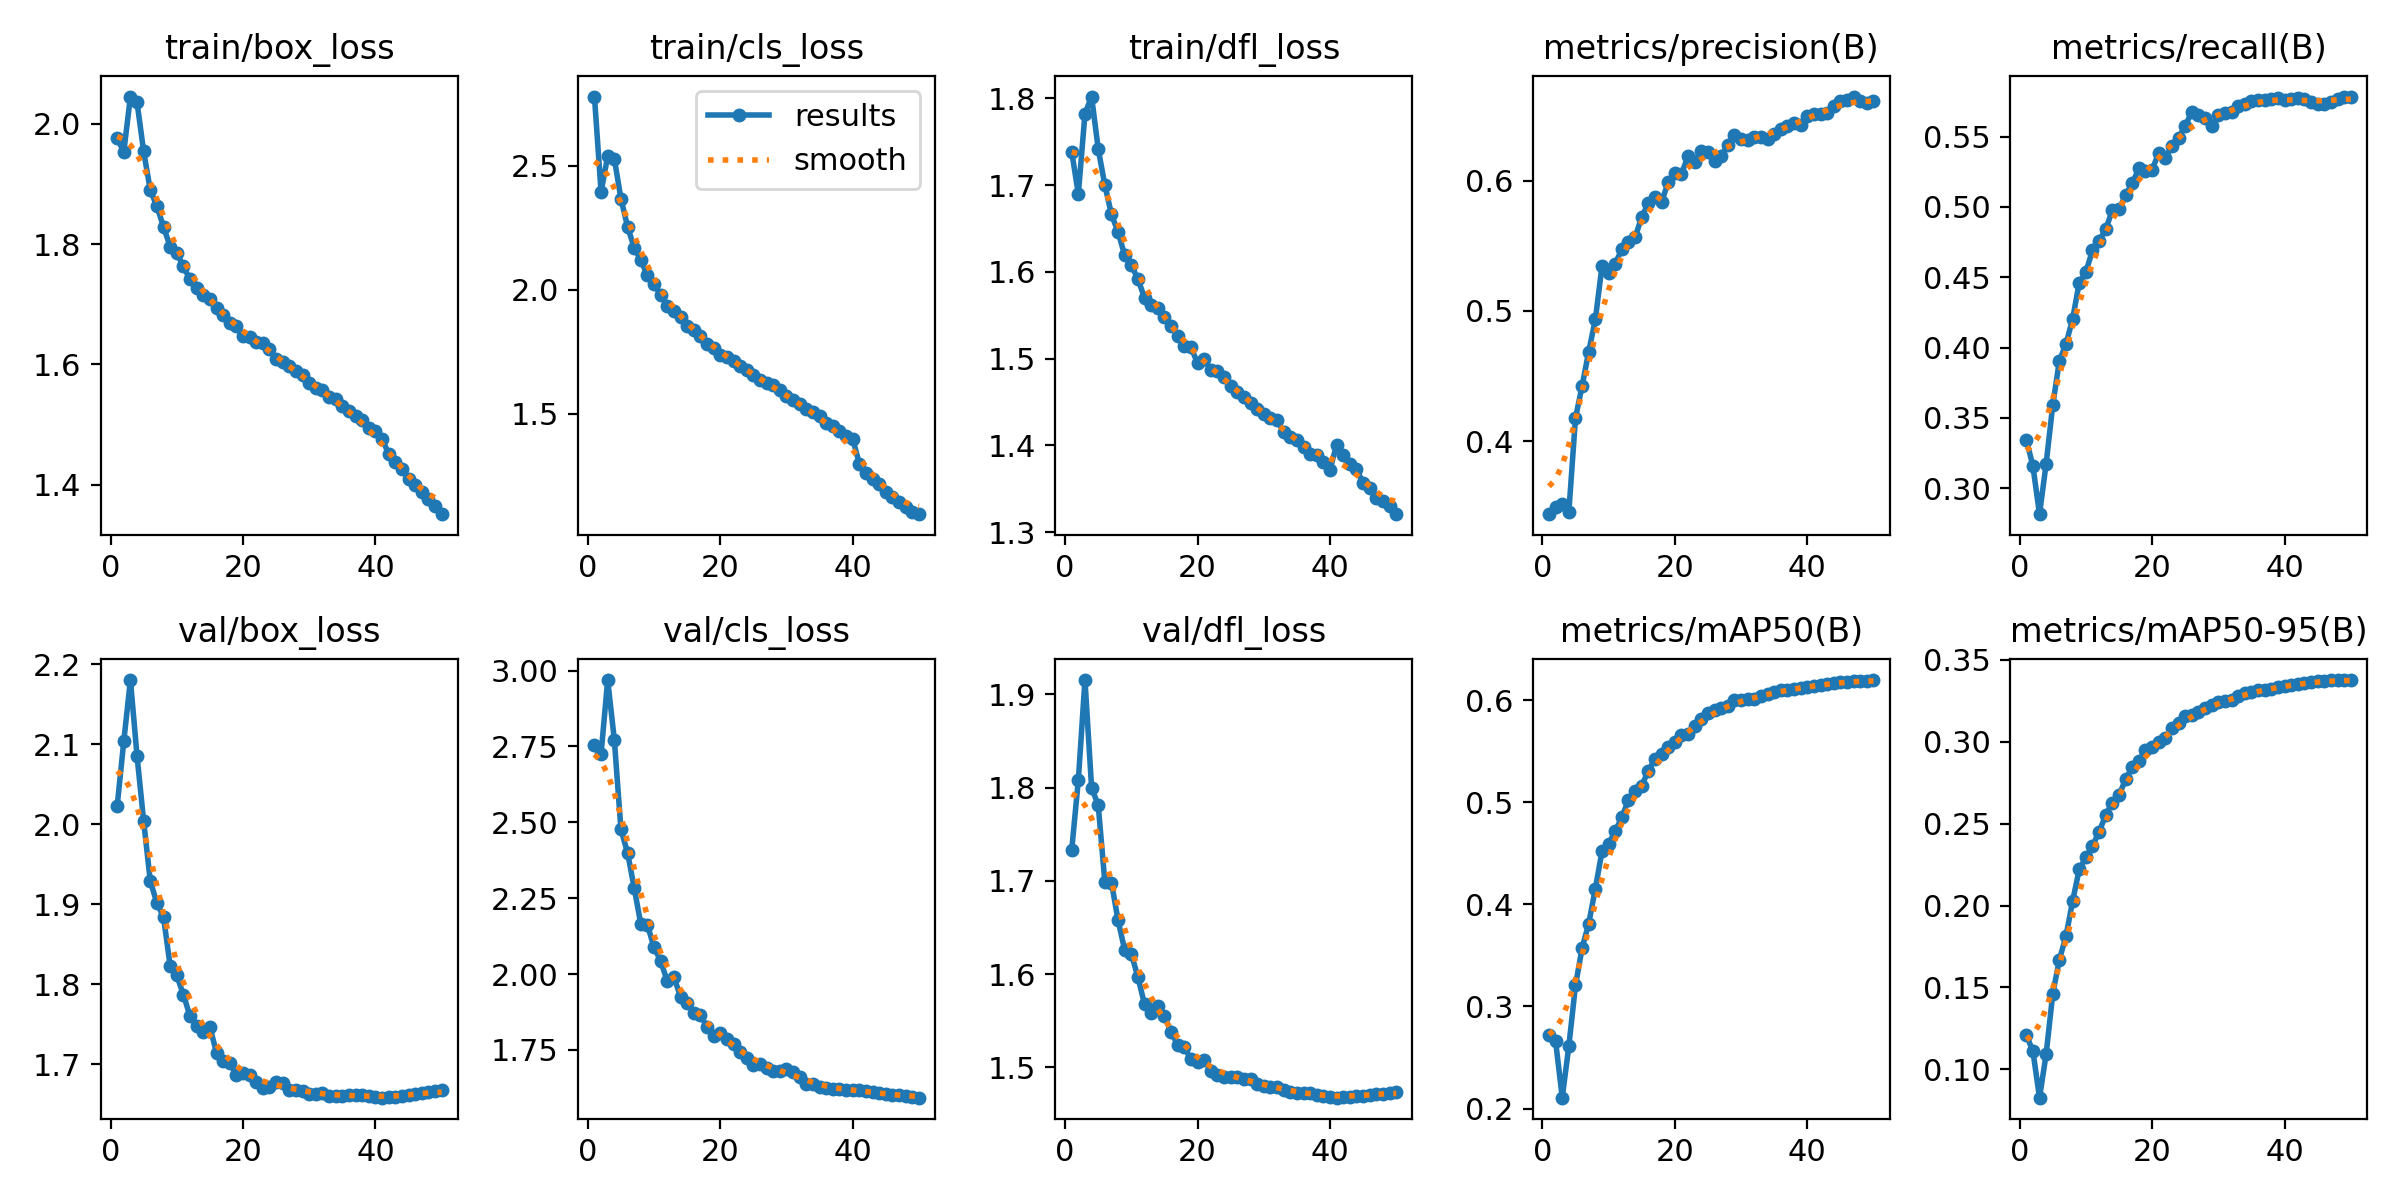


confusion_matrix.png


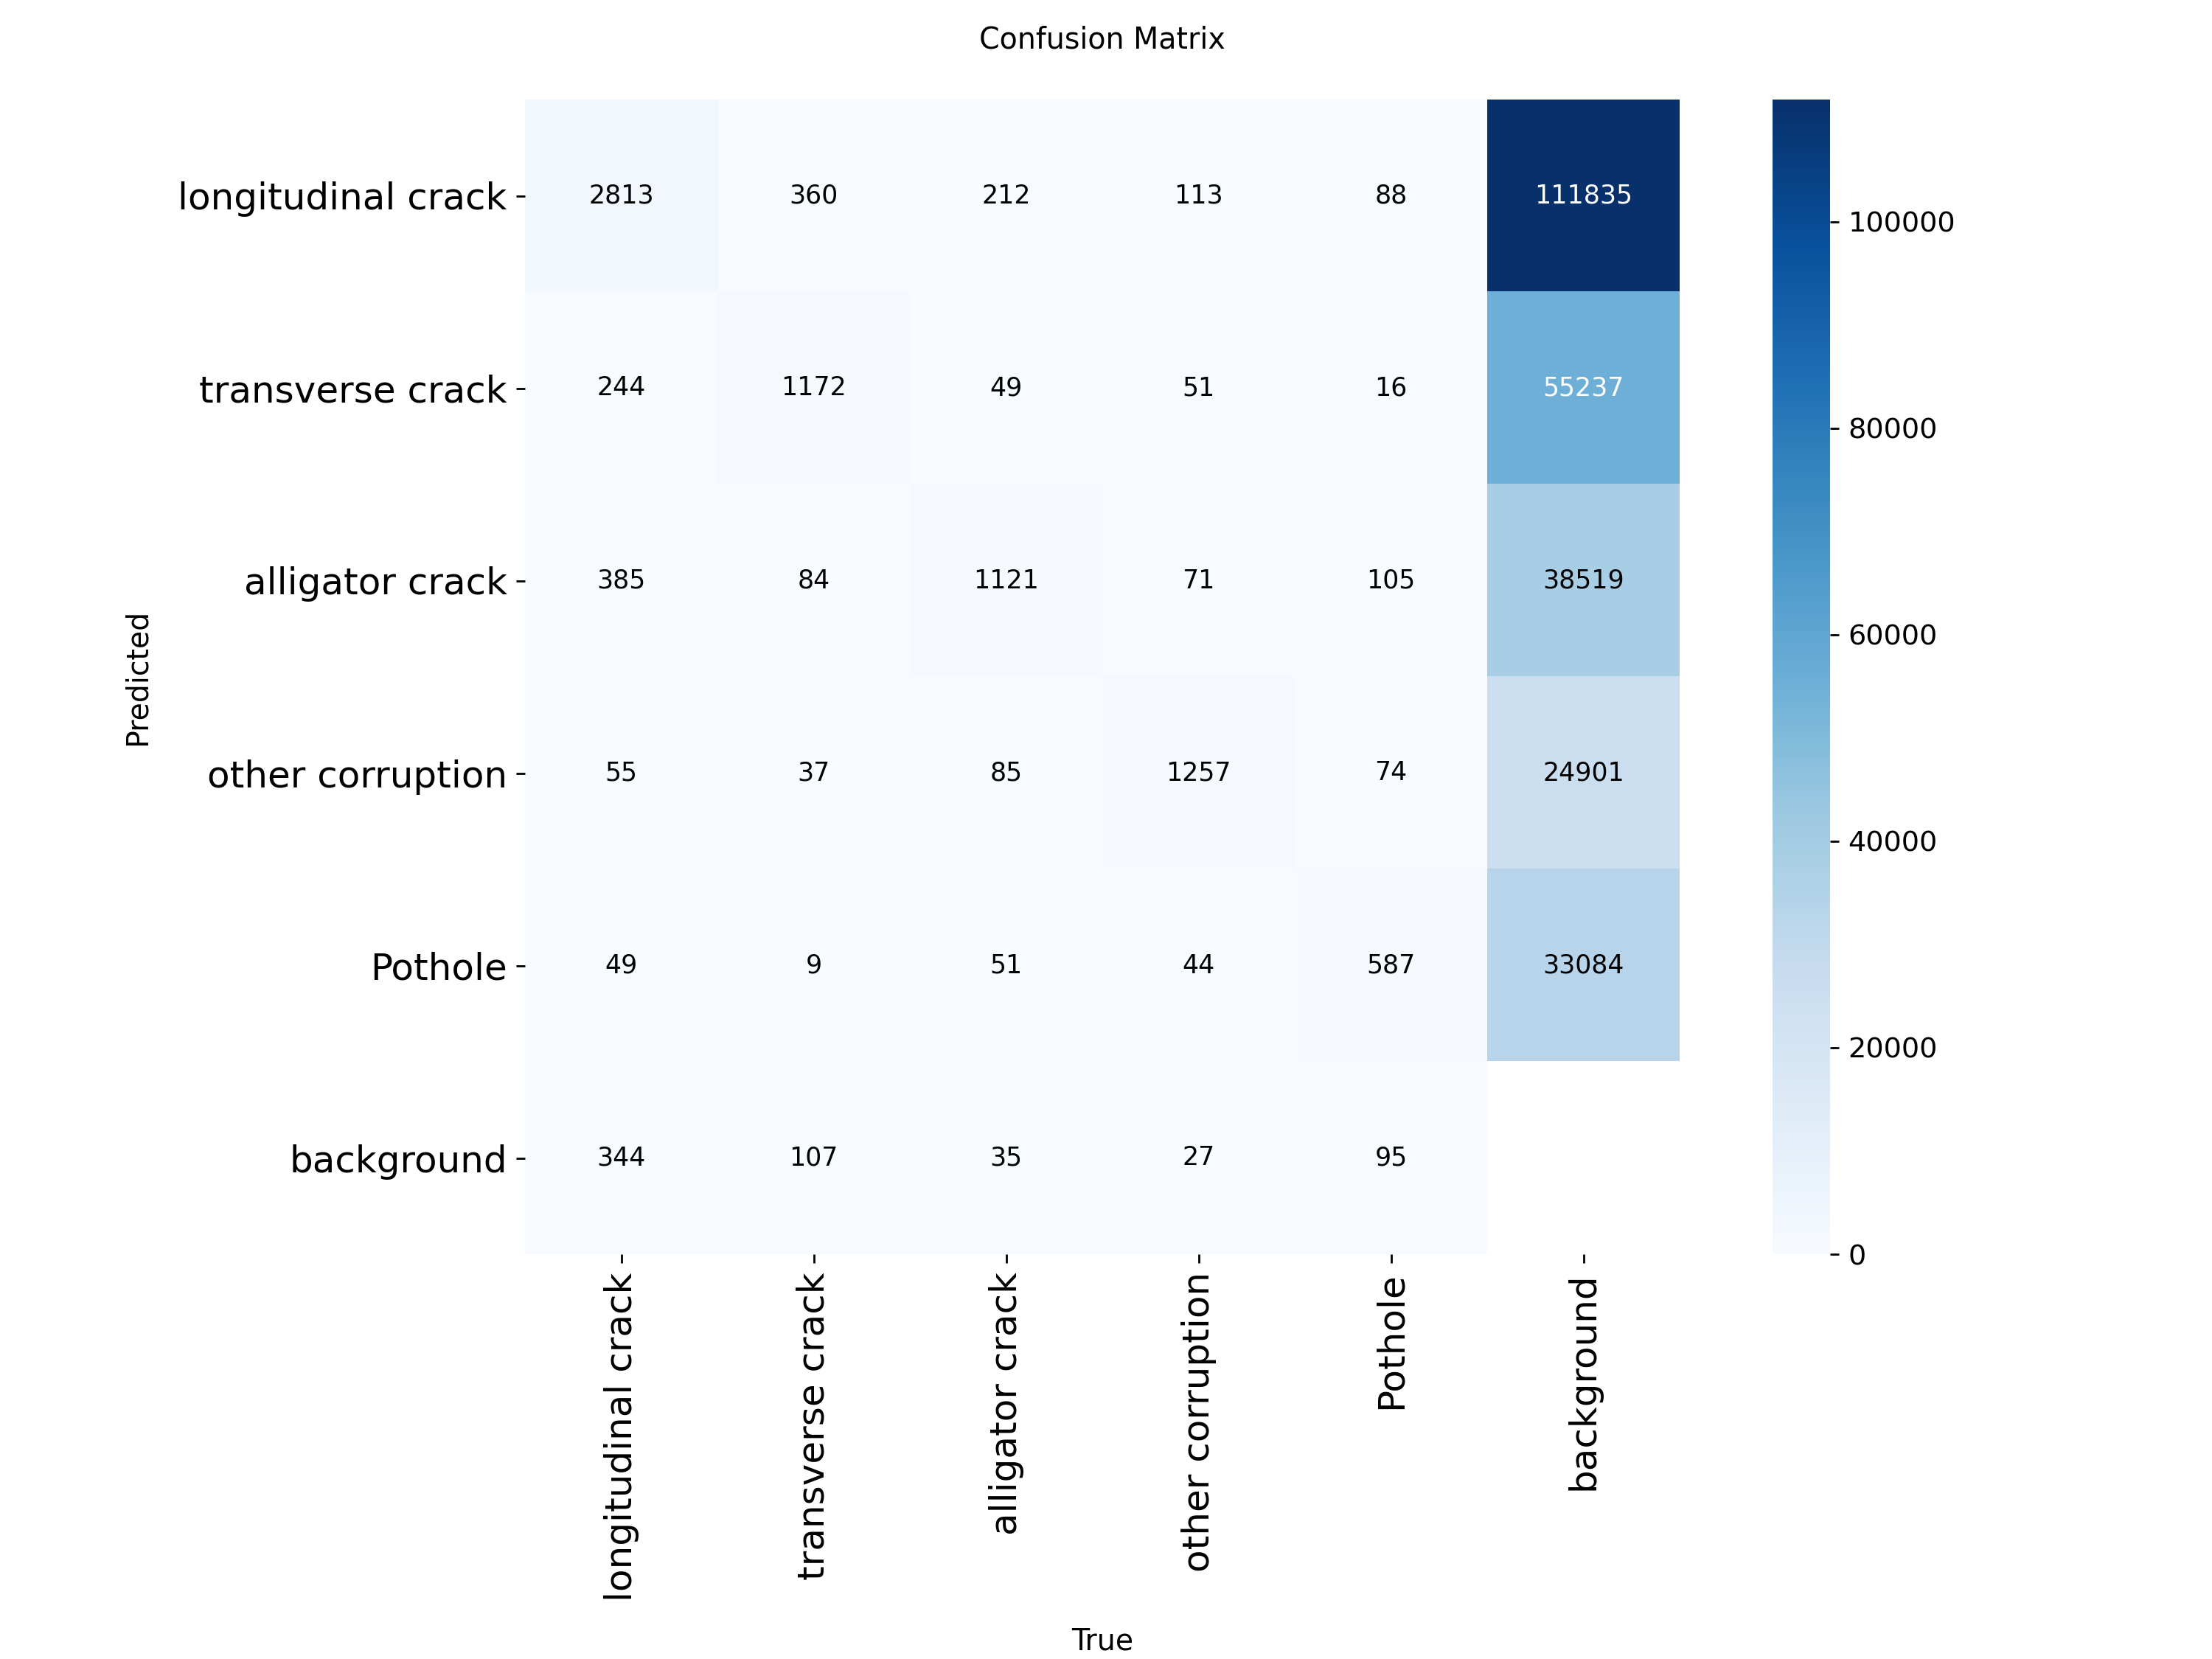


confusion_matrix_normalized.png


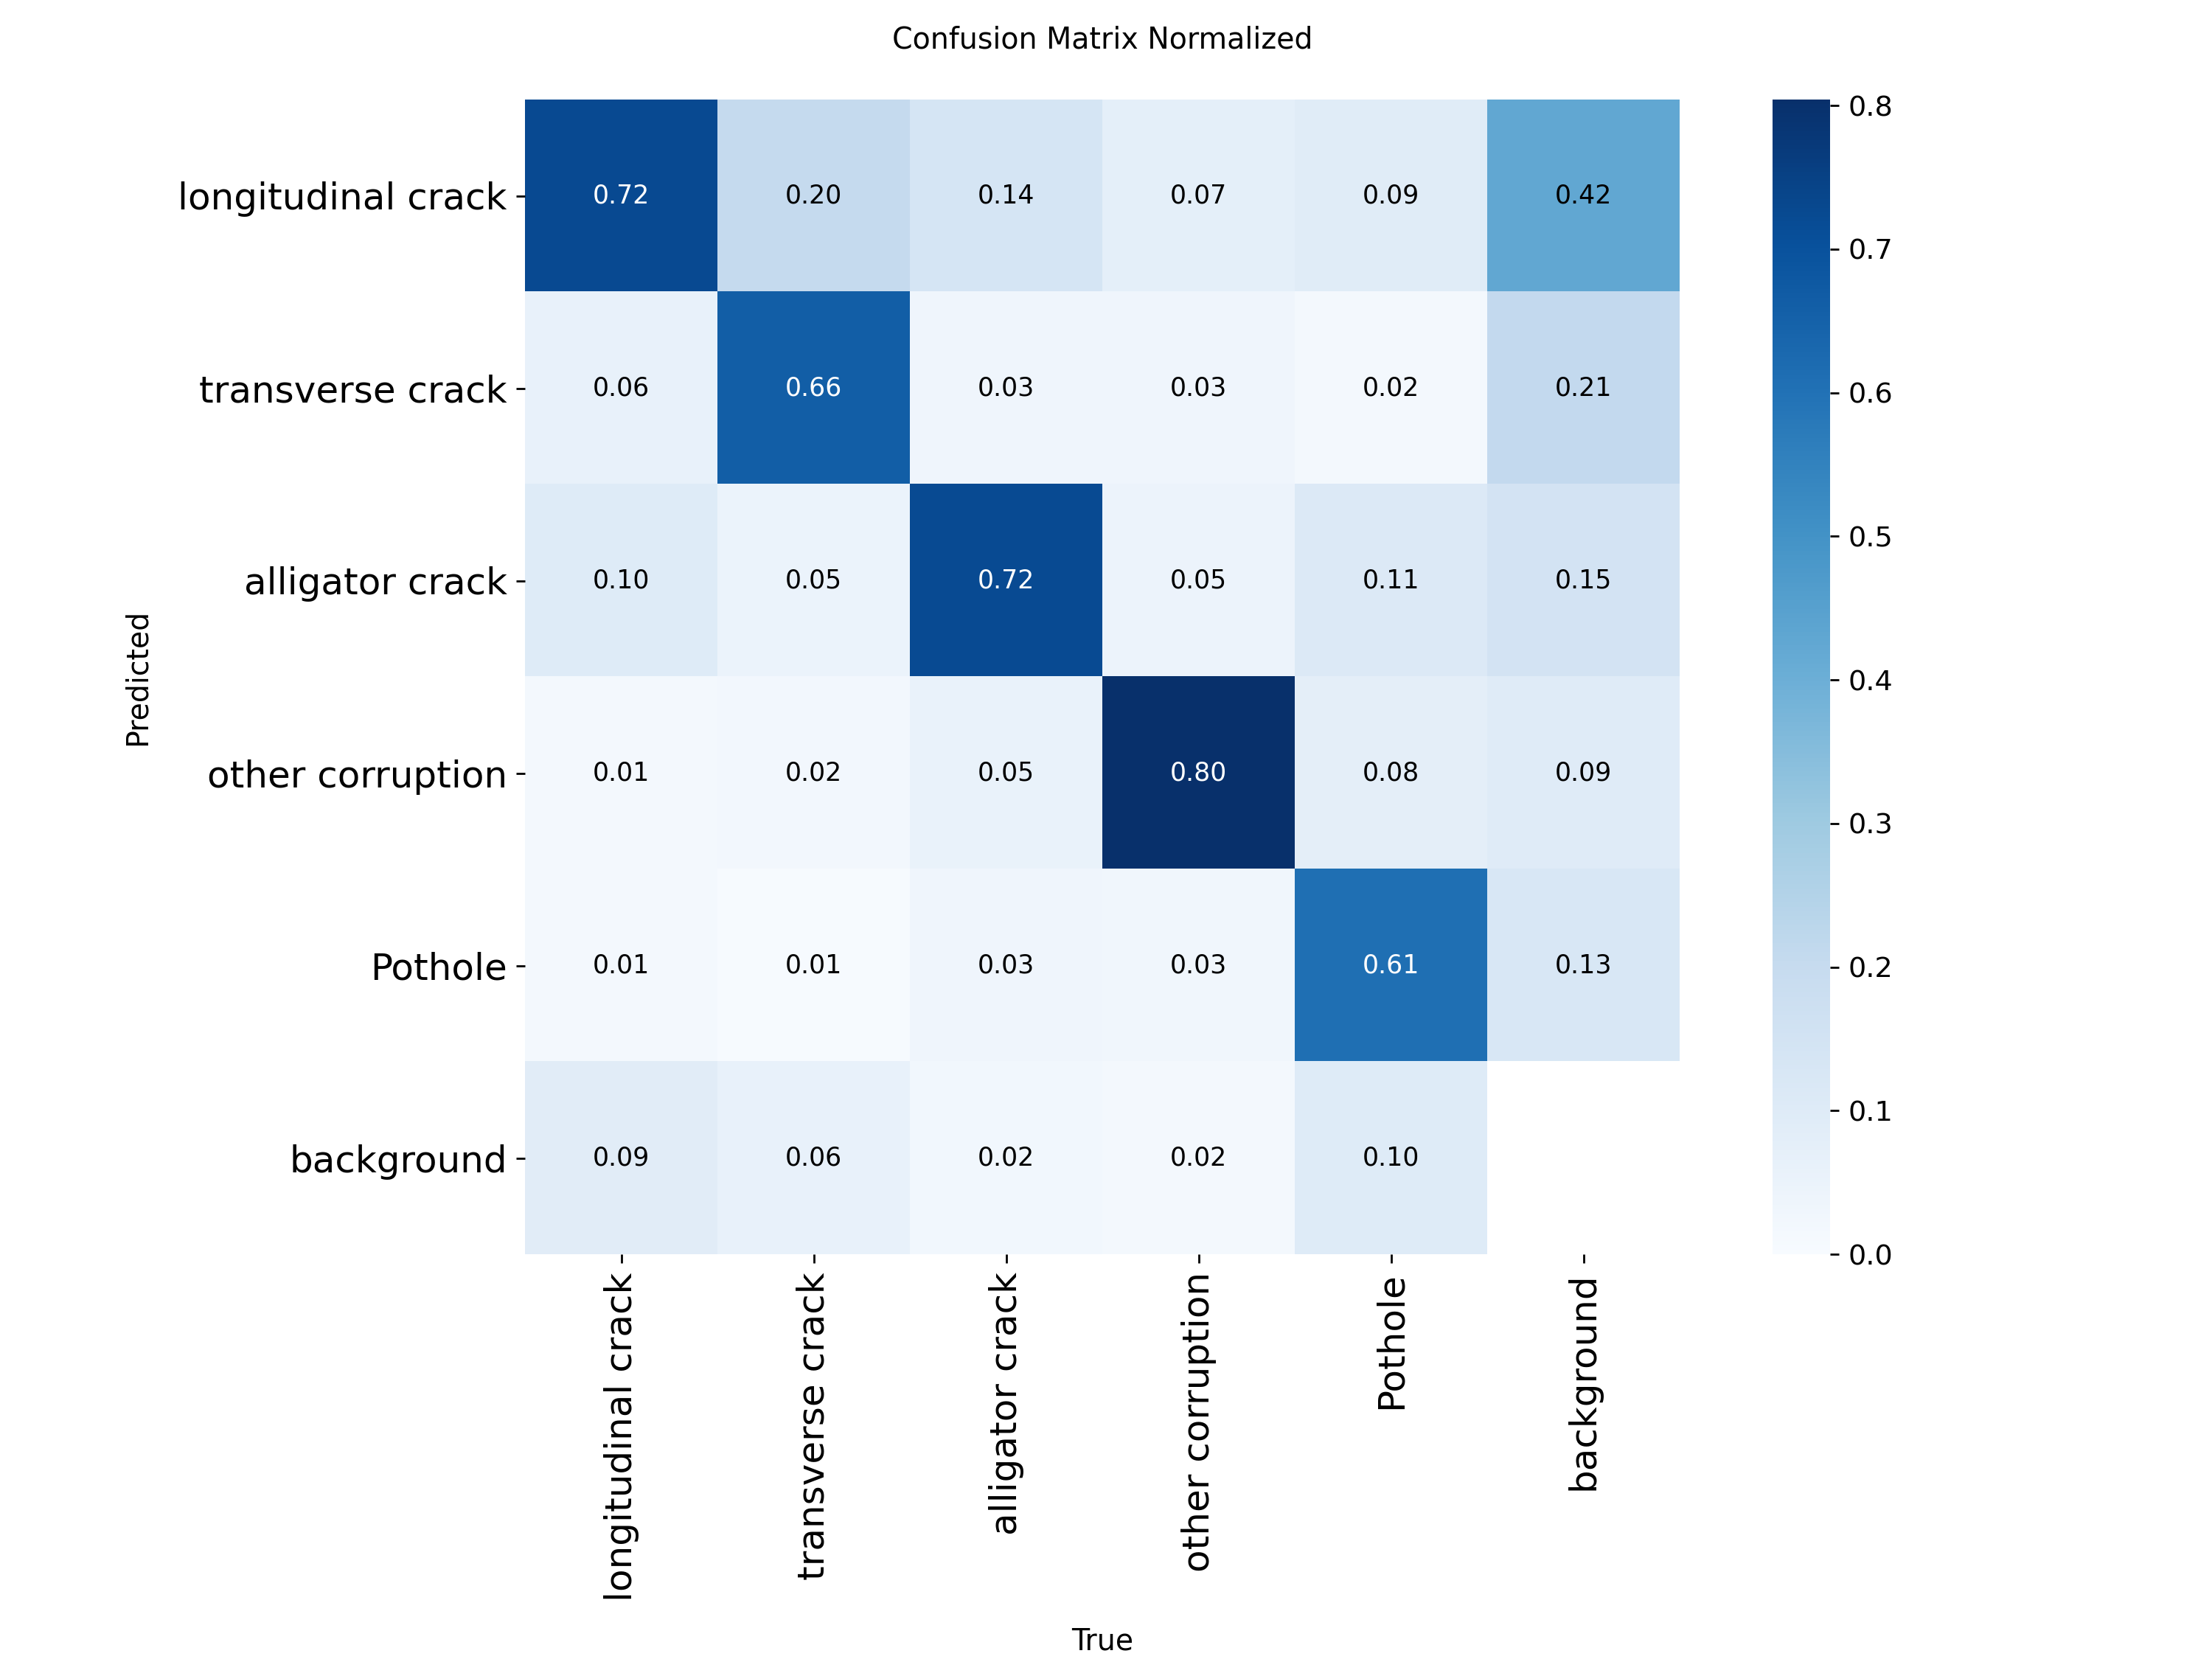


BoxPR_curve.png


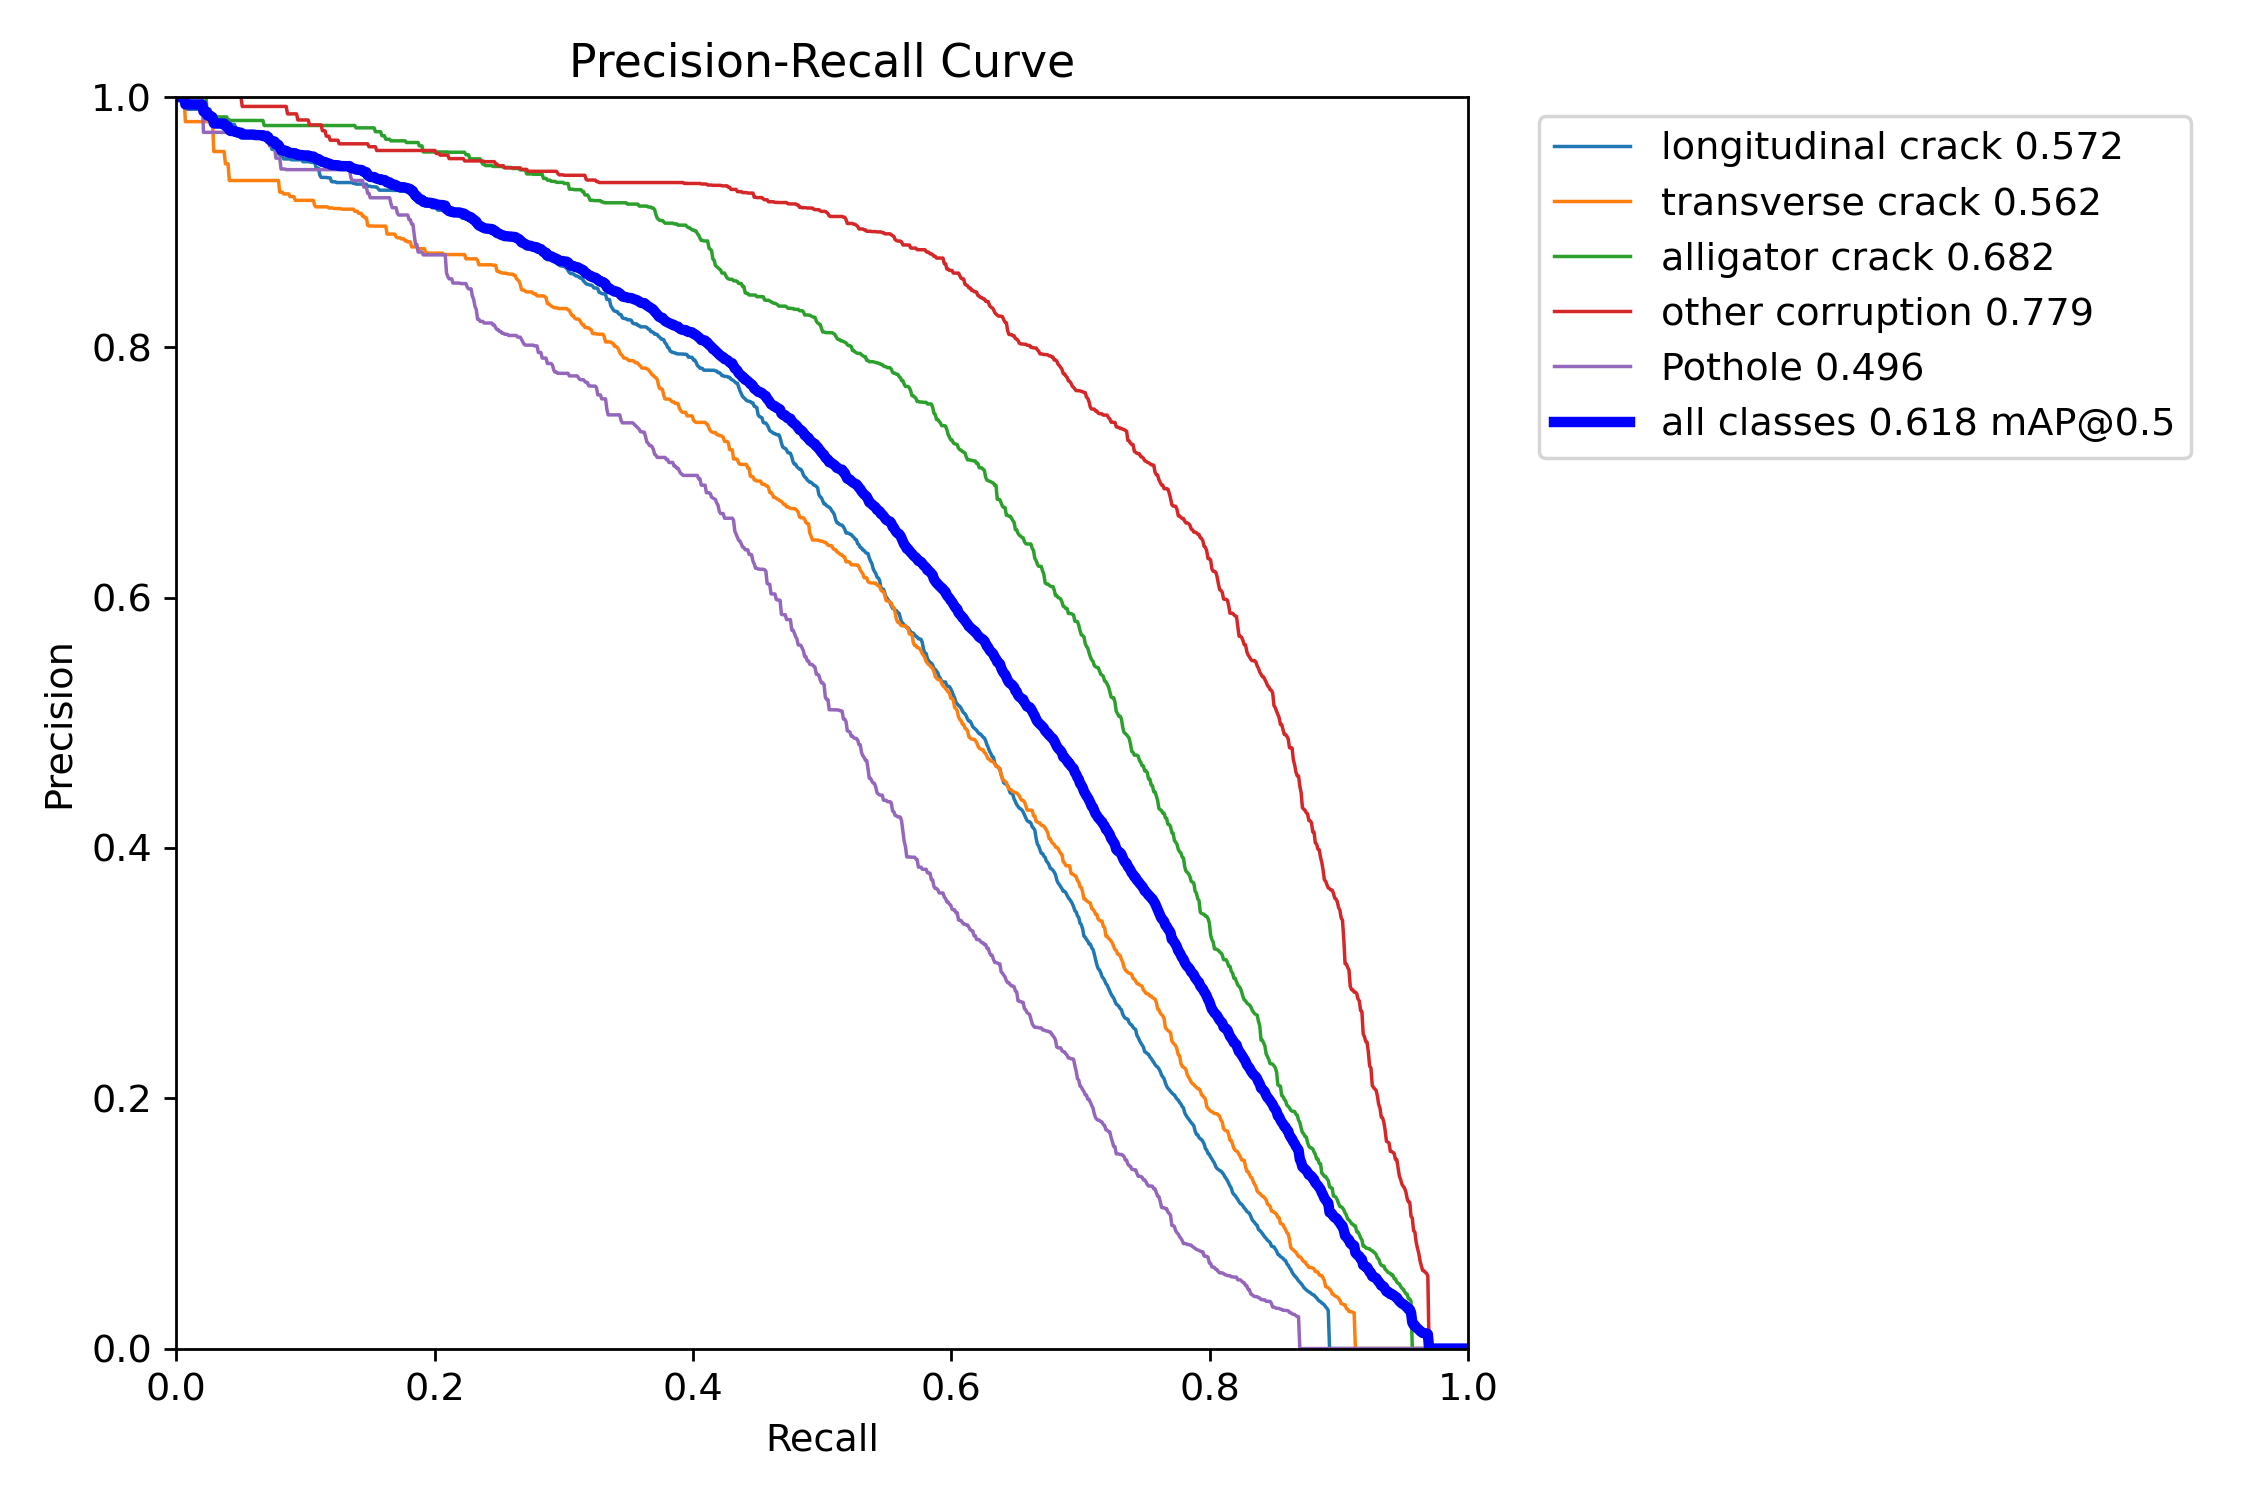


BoxF1_curve.png


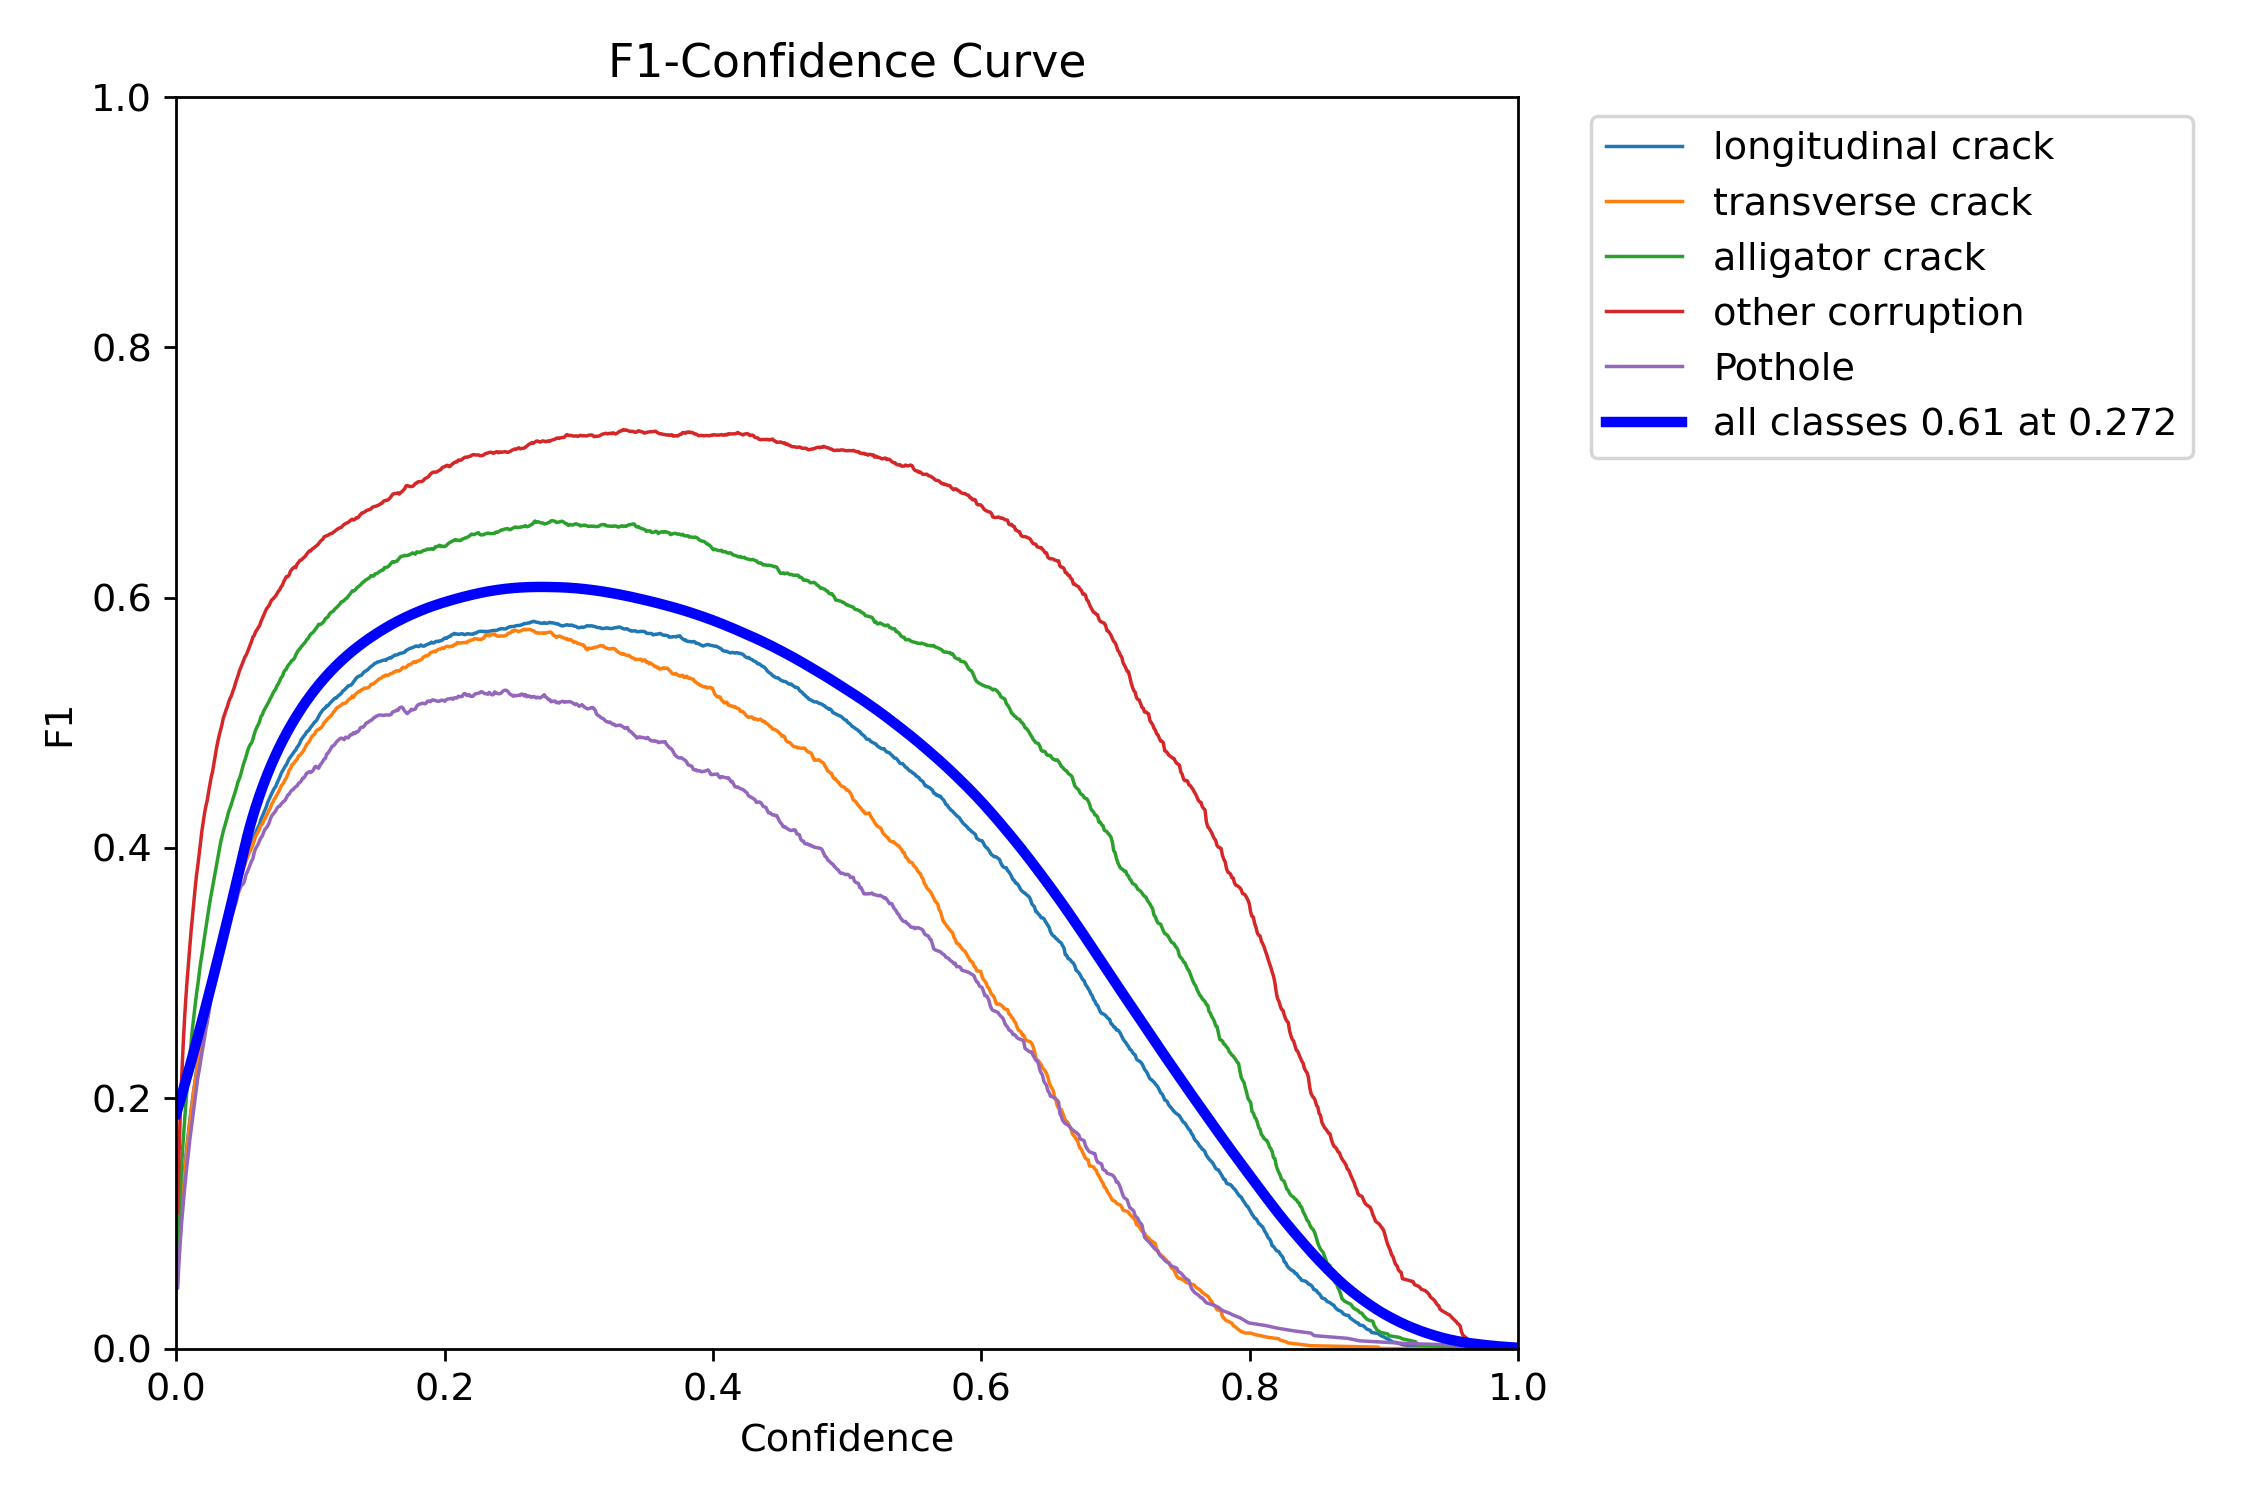


BoxP_curve.png


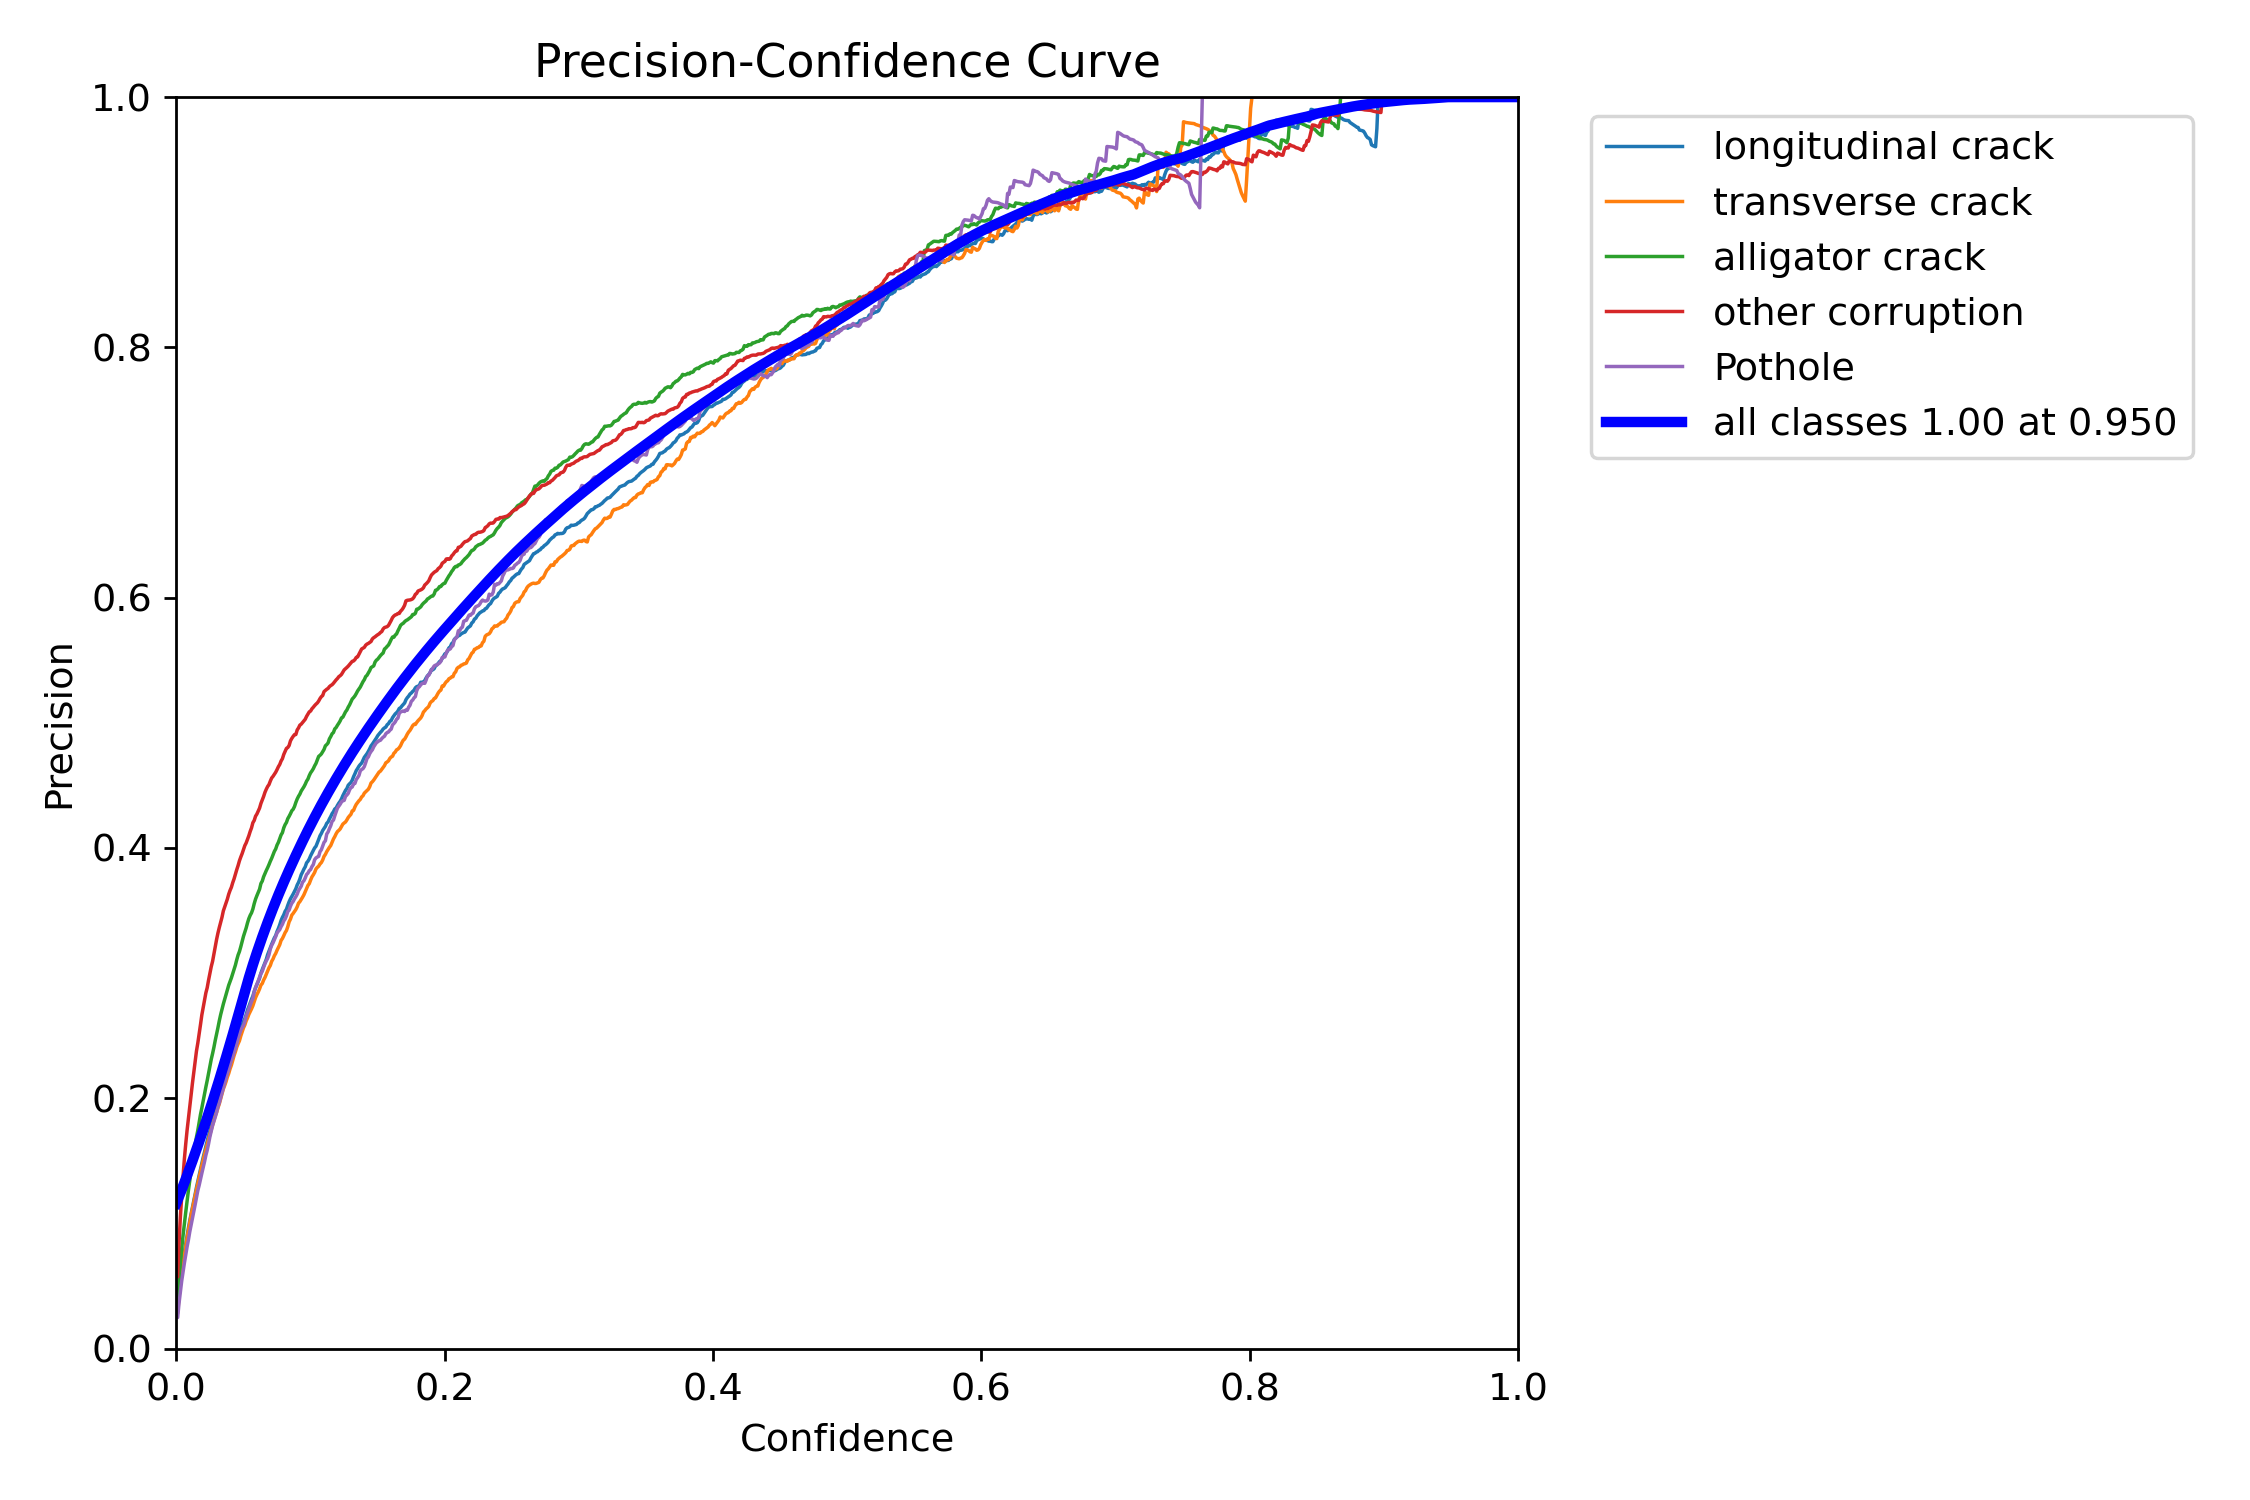


BoxR_curve.png


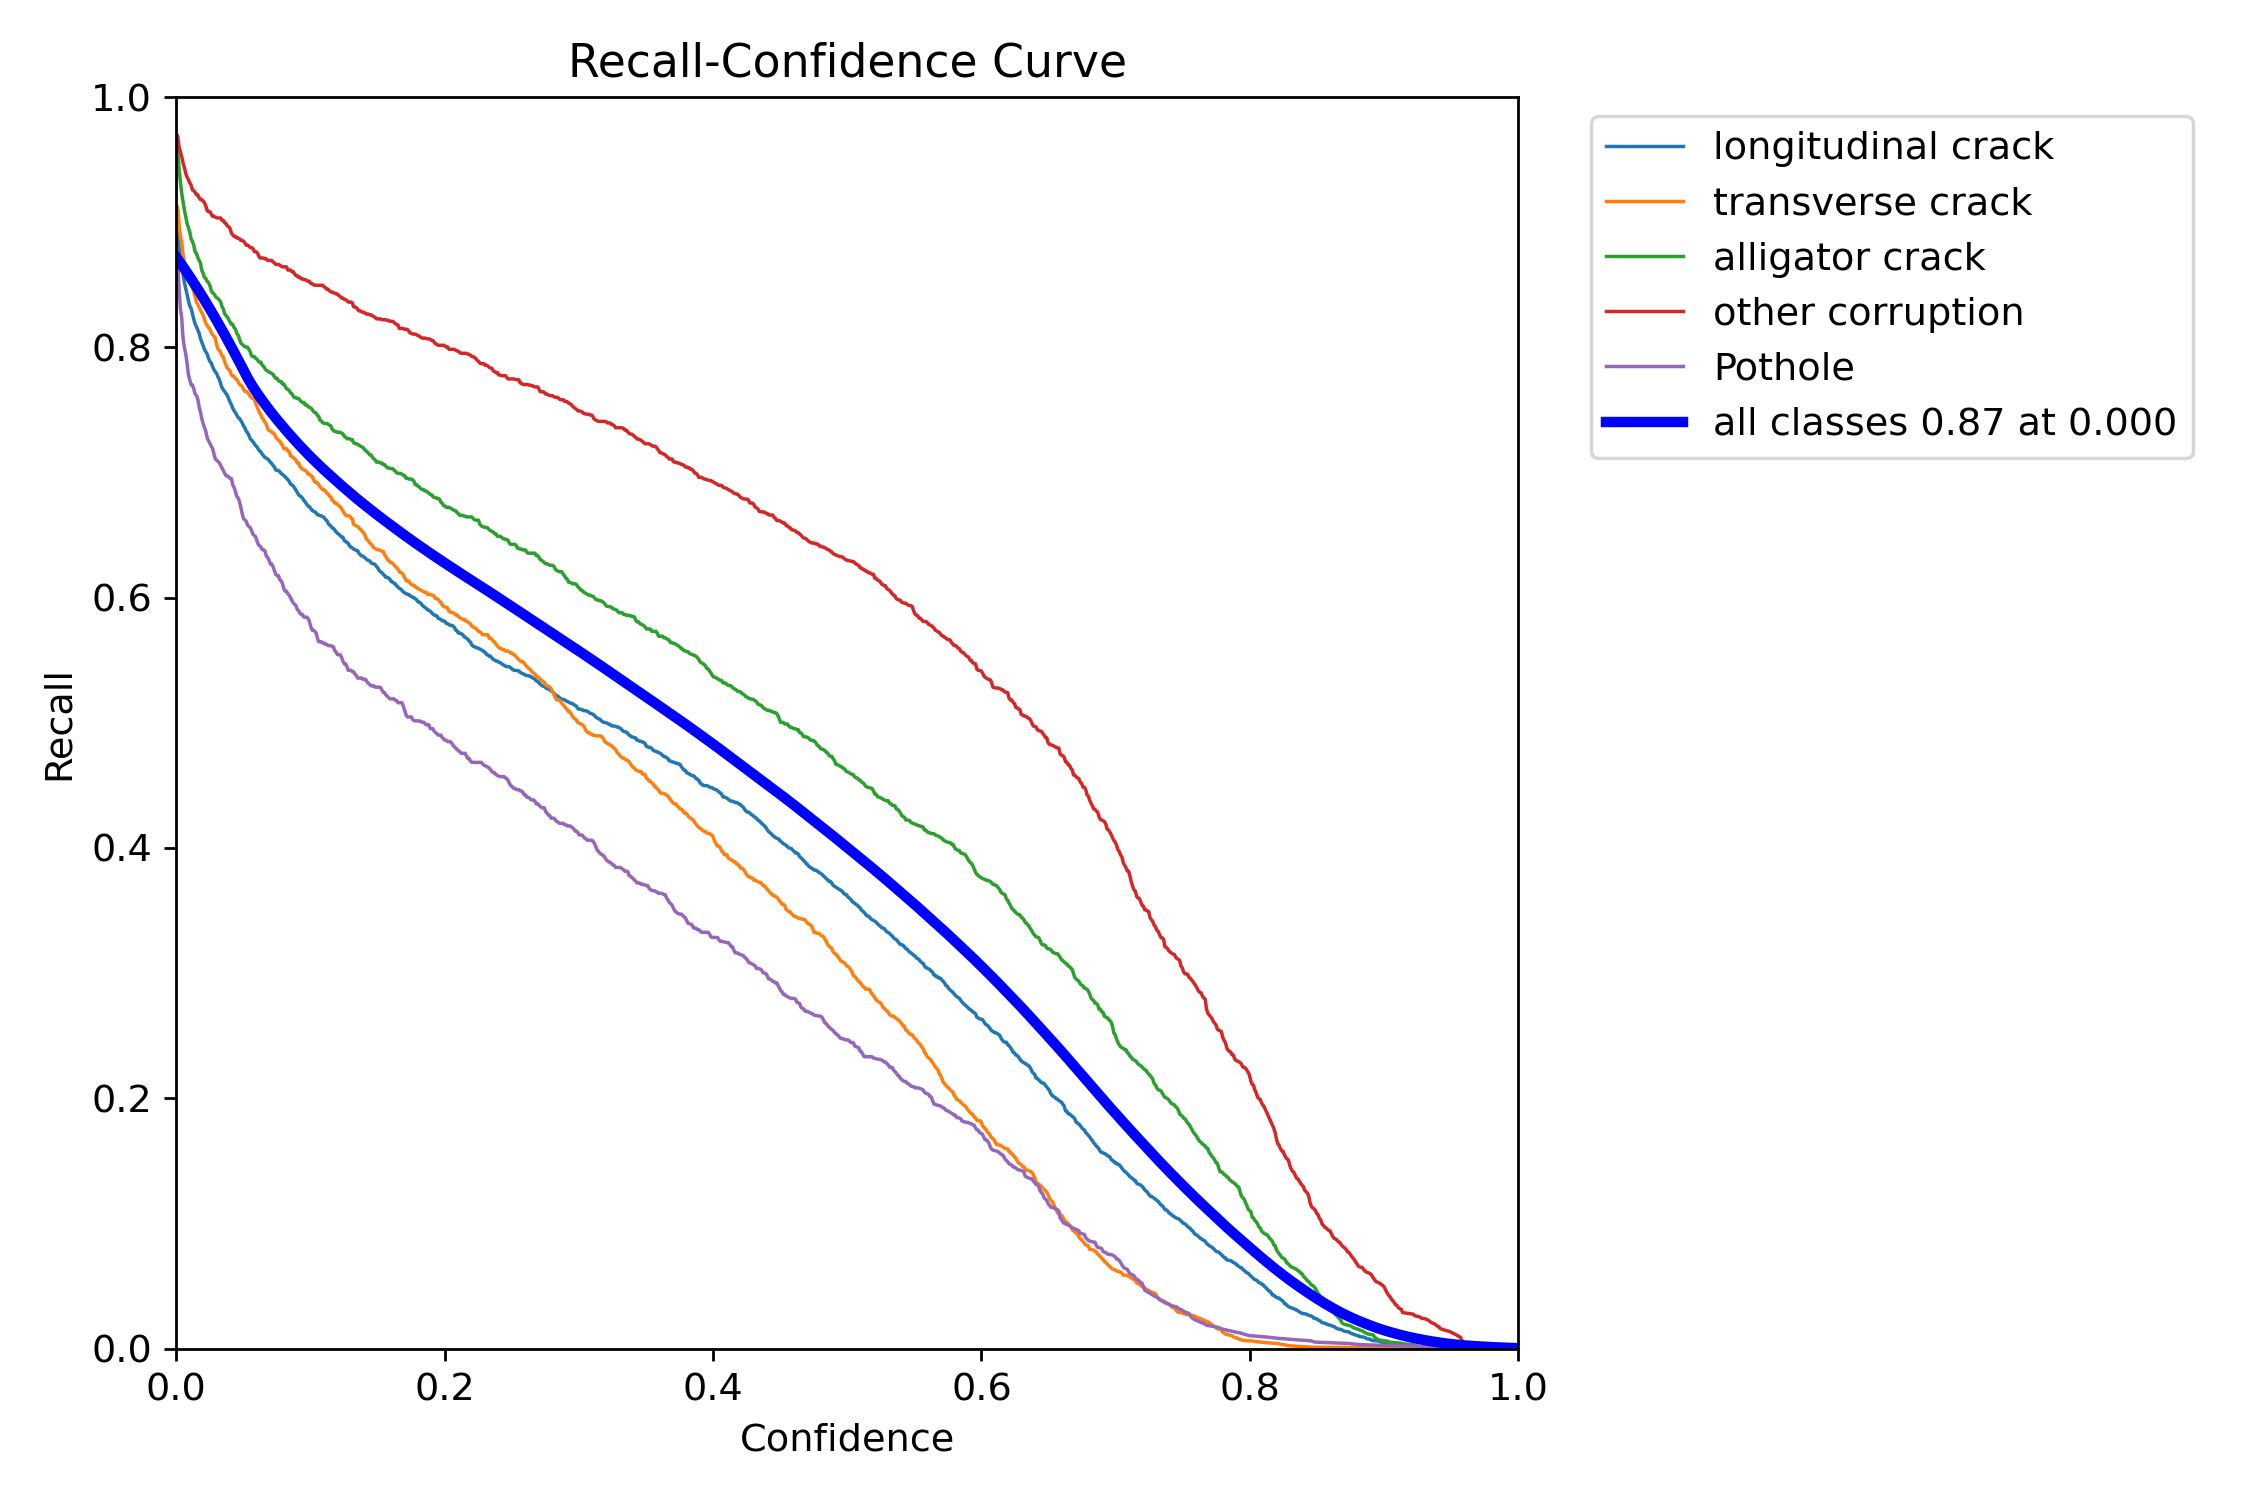

In [19]:
from IPython.display import Image, display
from pathlib import Path

RUN_DIRECTORY = Path("/kaggle/working/RoadDamageProject/YOLOv8s_RDD2022_5class")

images = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
]

for img in images:
    path = RUN_DIRECTORY / img
    if path.exists():
        print(f"\n{img}")
        display(Image(filename=str(path)))

In [20]:
import pandas as pd
from pathlib import Path

results_csv = Path(
    "/kaggle/working/RoadDamageProject/YOLOv8s_RDD2022_5class/results.csv"
)

results = pd.read_csv(results_csv)

display(results)

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
0,1,627.452,1.97580,2.78008,1.73828,0.34381,0.33448,0.27195,0.12097,2.02277,2.75647,1.73321,0.009994,0.003331,0.009994,0.003331,0.009994,0.003331,0.009994,0.003331
1,2,1206.250,1.95316,2.39602,1.68963,0.34932,0.31580,0.26573,0.11113,2.10399,2.72590,1.80824,0.019598,0.006533,0.019598,0.006533,0.019598,0.006533,0.019598,0.006533
2,3,1767.580,2.04532,2.53960,1.78213,0.35190,0.28145,0.21062,0.08265,2.18048,2.96902,1.91545,0.028806,0.009602,0.028806,0.009602,0.028806,0.009602,0.028806,0.009602
3,4,2321.870,2.03584,2.53003,1.80199,0.34575,0.31734,0.26138,0.10920,2.08554,2.77289,1.80001,0.028218,0.009406,0.028218,0.009406,0.028218,0.009406,0.028218,0.009406
4,5,2876.400,1.95400,2.36811,1.74161,0.41770,0.35906,0.32053,0.14612,2.00393,2.47689,1.78124,0.027624,0.009208,0.027624,0.009208,0.027624,0.009208,0.027624,0.009208
5,6,3430.480,1.88982,2.25490,1.70008,0.44234,0.39058,0.35722,0.16698,1.92909,2.39981,1.69912,0.027030,0.009010,0.027030,0.009010,0.027030,0.009010,0.027030,0.009010
6,7,3984.700,1.86276,2.17090,1.66610,0.46881,0.40262,0.38114,0.18129,1.90138,2.28436,1.69827,0.026436,0.008812,0.026436,0.008812,0.026436,0.008812,0.026436,0.008812
7,8,4539.440,1.82867,2.11997,1.64593,0.49348,0.42021,0.41528,0.20279,1.88404,2.16471,1.65766,0.025842,0.008614,0.025842,0.008614,0.025842,0.008614,0.025842,0.008614
8,9,5093.950,1.79558,2.05918,1.61889,0.53437,0.44621,0.45177,0.22210,1.82271,2.16204,1.62580,0.025248,0.008416,0.025248,0.008416,0.025248,0.008416,0.025248,0.008416
9,10,5649.270,1.78511,2.02299,1.60762,0.52941,0.45374,0.45887,0.22948,1.81089,2.08770,1.62185,0.024654,0.008218,0.024654,0.008218,0.024654,0.008218,0.024654,0.008218


In [21]:
print("Final Epoch Results")
print("=" * 50)

display(results.tail(1))

Final Epoch Results


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
49,50,27806.2,1.35074,1.09575,1.32059,0.6617,0.57852,0.61954,0.33764,1.66735,1.59242,1.47365,0.000894,0.000298,0.000894,0.000298,0.000894,0.000298,0.000894,0.000298


In [22]:
last = results.iloc[-1]

print(f"Precision (B): {last['metrics/precision(B)']:.4f}")
print(f"Recall (B):    {last['metrics/recall(B)']:.4f}")
print(f"mAP50 (B):     {last['metrics/mAP50(B)']:.4f}")
print(f"mAP50-95 (B):  {last['metrics/mAP50-95(B)']:.4f}")

Precision (B): 0.6617
Recall (B):    0.5785
mAP50 (B):     0.6195
mAP50-95 (B):  0.3376


## 7. Prediction examples

Shows validation images with the predictions made by the trained model.

val_batch0_pred.jpg


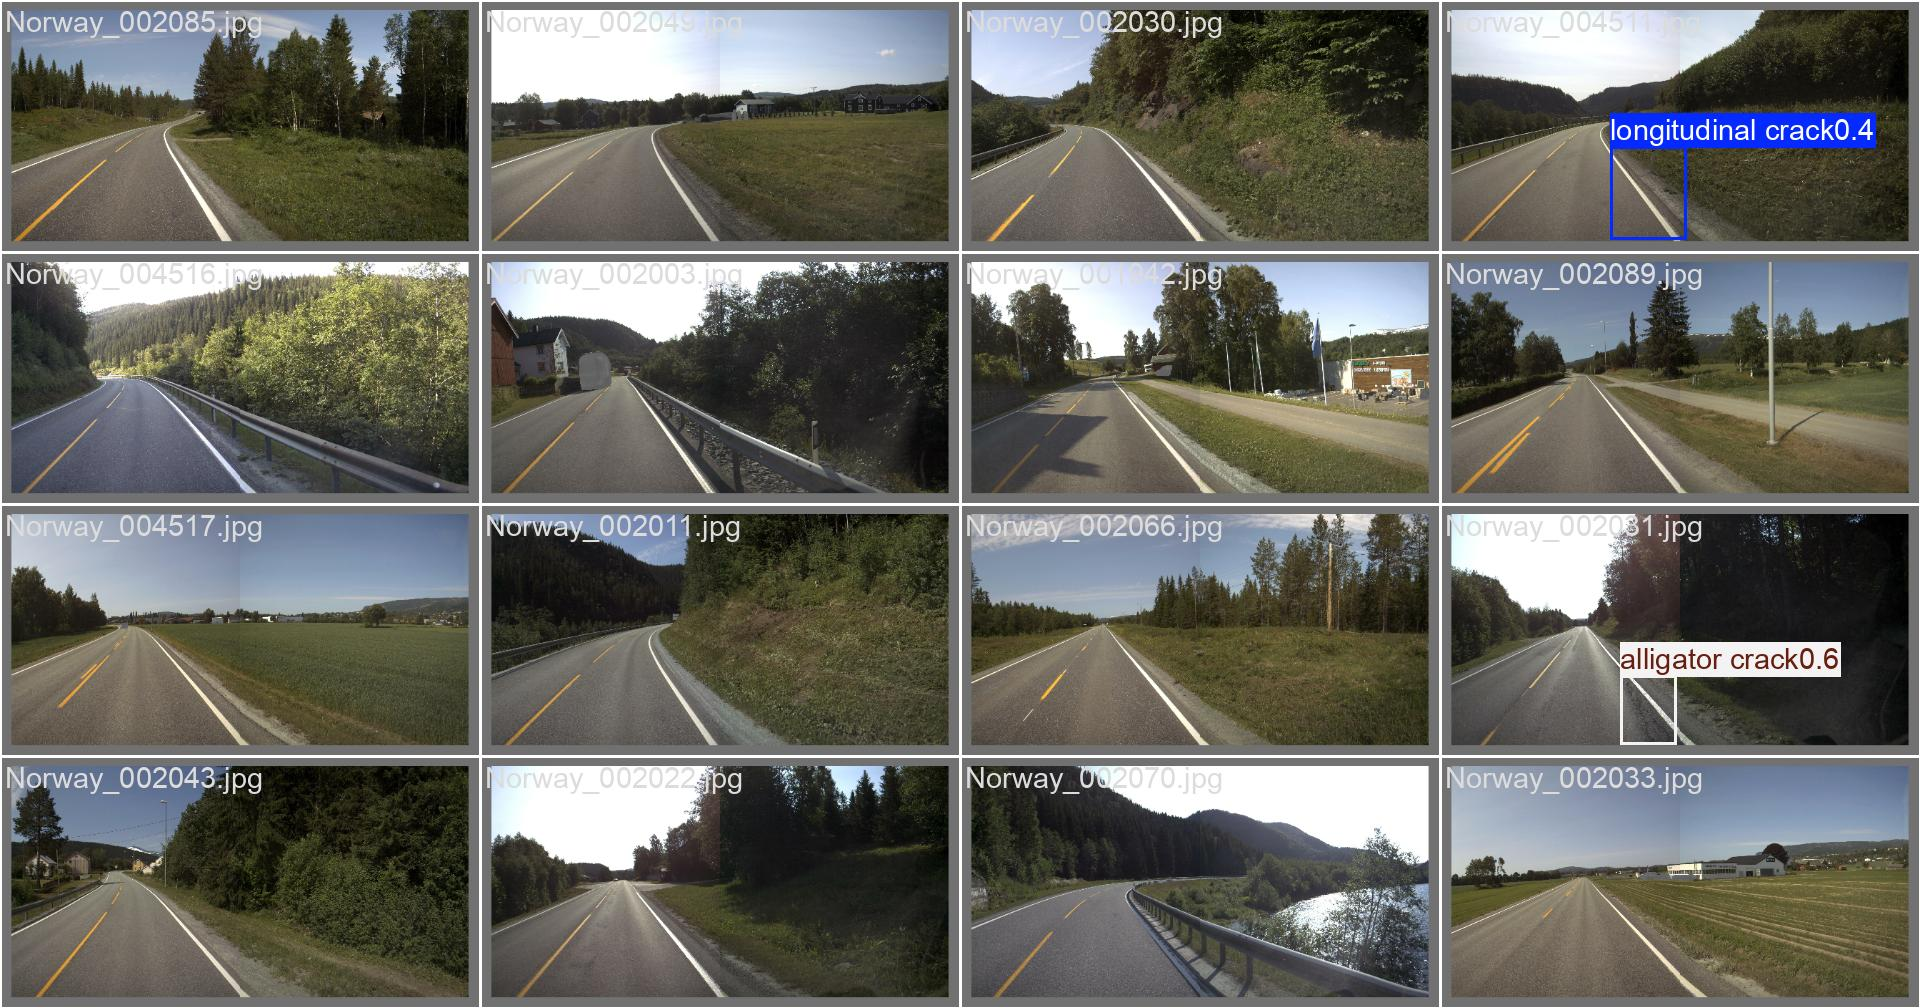

val_batch1_pred.jpg


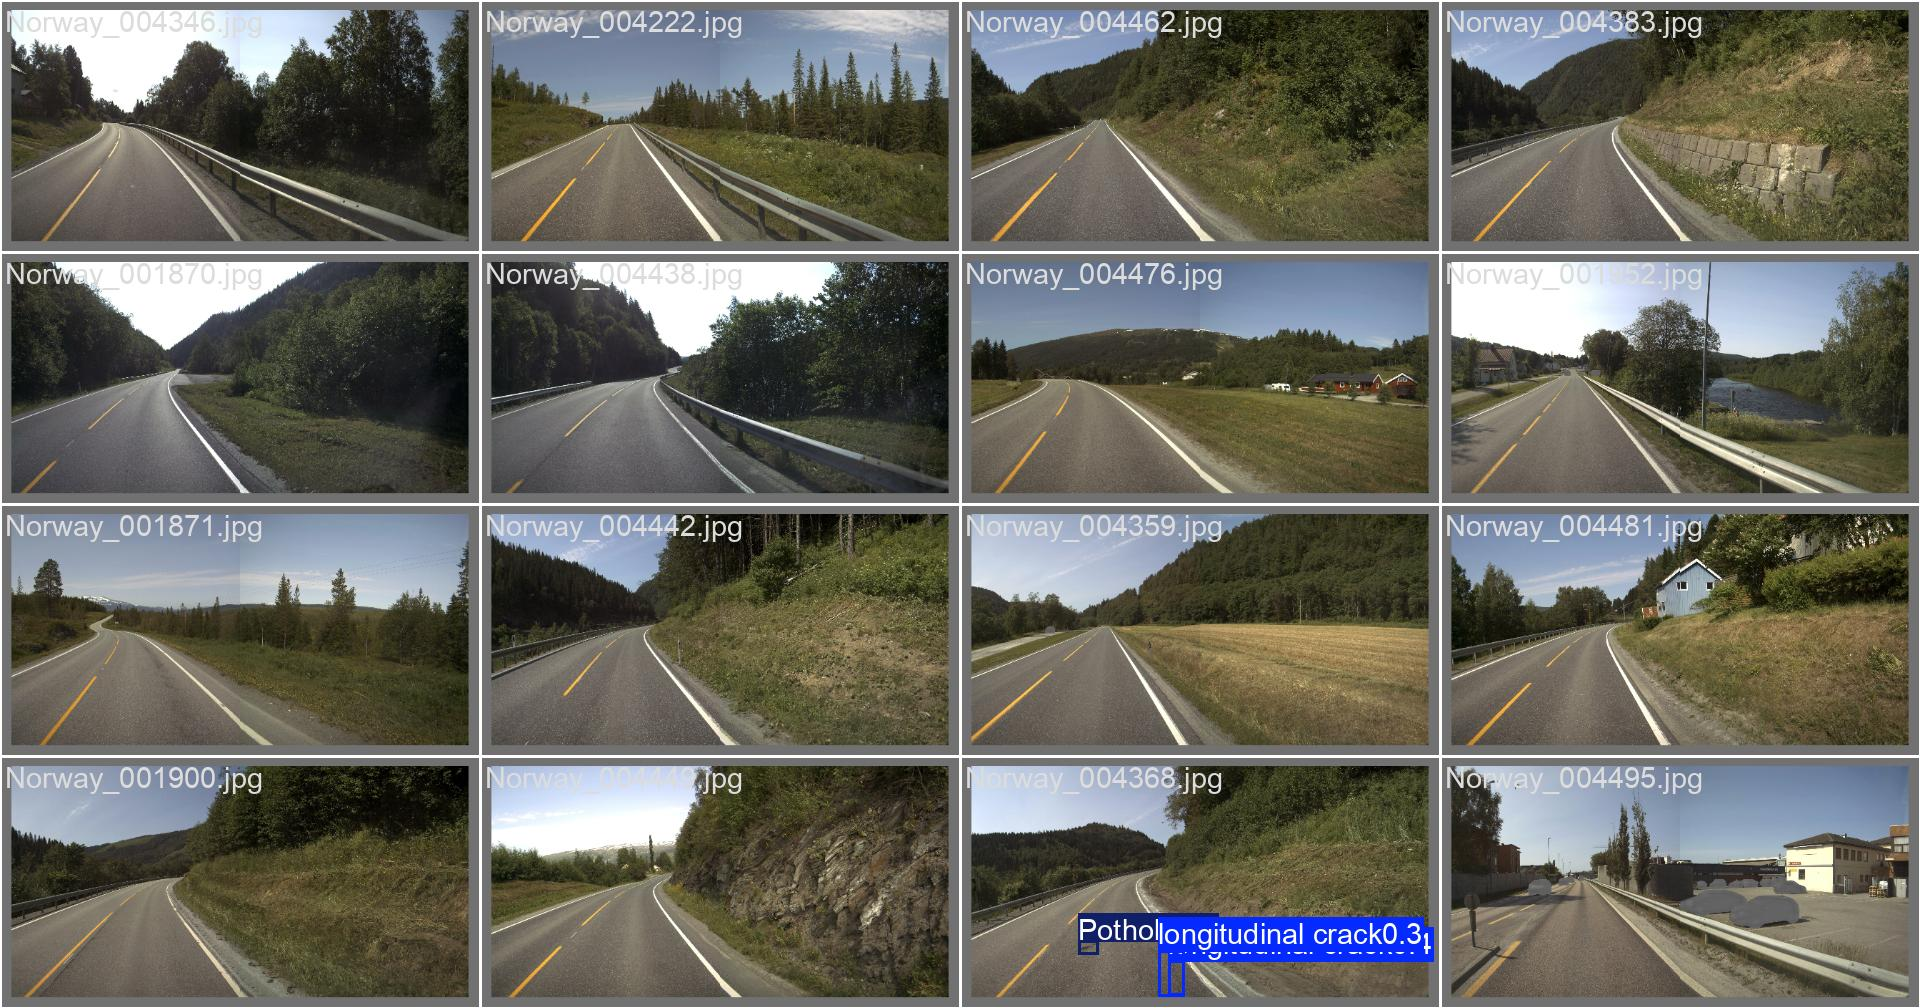

val_batch2_pred.jpg


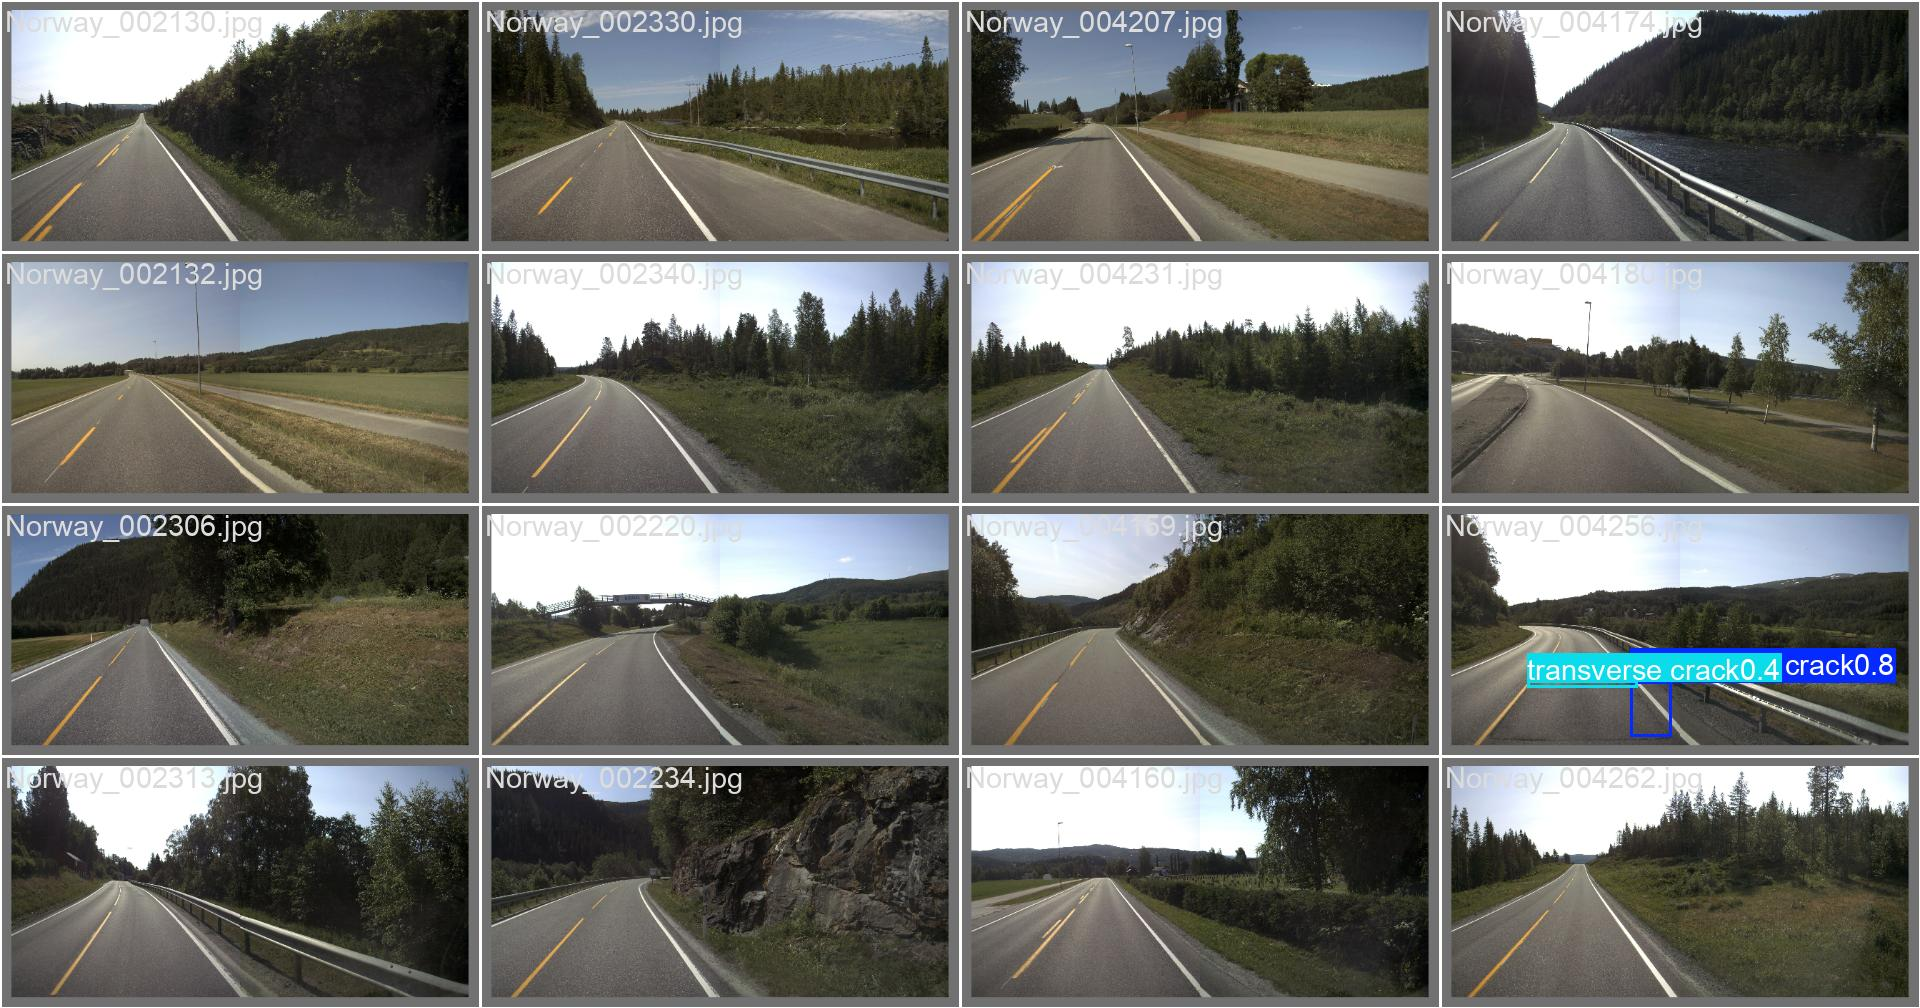

In [23]:
from IPython.display import Image, display
from pathlib import Path

RUN_DIRECTORY = Path("/kaggle/working/RoadDamageProject/YOLOv8s_RDD2022_5class")

for img in [
    "val_batch0_pred.jpg",
    "val_batch1_pred.jpg",
    "val_batch2_pred.jpg",
]:
    path = RUN_DIRECTORY / img
    if path.exists():
        print(img)
        display(Image(filename=str(path)))